In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import glob

from micom import load_pickle
from micom.qiime_formats import load_qiime_model_db, load_qiime_medium
from micom.workflows import grow, save_results, load_results
from micom.viz import *
from micom.measures import *
from micom.viz.interactions import plot_focal_interactions
from micom.interaction.scores import MES

# pFBA

In [2]:
pfba_lf0 = load_results("results/lf0/growth_pfba.zip")
pfba_hf0 = load_results("results/hf0/growth_pfba.zip")

## Growth

In [3]:
growth_lf0 = pfba_lf0.growth_rates
growth_lf0['diet'] = 'LF/HPP'
growth_hf0 = pfba_hf0.growth_rates
growth_hf0['diet'] = 'HF/HS'
growth = pd.concat([growth_lf0, growth_hf0], axis=0, ignore_index=True)
growth

,abundance,growth_rate,reactions,metabolites,taxon,tradeoff,sample_id,diet
0,0.097084,0.000000e+00,2381,1461,B_caccae,0.6,mouse_01,LF/HPP
1,0.444060,3.827201e-02,2779,1702,B_cellulosilyticus_WH2,0.6,mouse_01,LF/HPP
2,0.139322,0.000000e+00,2476,1526,B_ovatus,0.6,mouse_01,LF/HPP
3,0.093460,1.196529e-01,2524,1549,B_thetaiotaomicron,0.6,mouse_01,LF/HPP
4,0.035084,0.000000e+00,2418,1500,B_uniformis,0.6,mouse_01,LF/HPP
...,...,...,...,...,...,...,...,...
160,0.004272,1.445009e-06,920,850,C_aerofaciens,0.6,mouse_15,HF/HS
161,0.019892,4.351052e-07,2049,1394,C_scindens,0.6,mouse_15,HF/HS
162,0.000125,2.261928e-04,1980,1313,C_spiroforme,0.6,mouse_15,HF/HS
163,0.034353,9.585098e-03,2519,1570,P_distasonis,0.6,mouse_15,HF/HS


/home/acs98/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/acs98/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/acs98/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(vector):
/home/acs98/.local/lib/python3.10/site-packages/seaborn/_oldcore.py:1498: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if

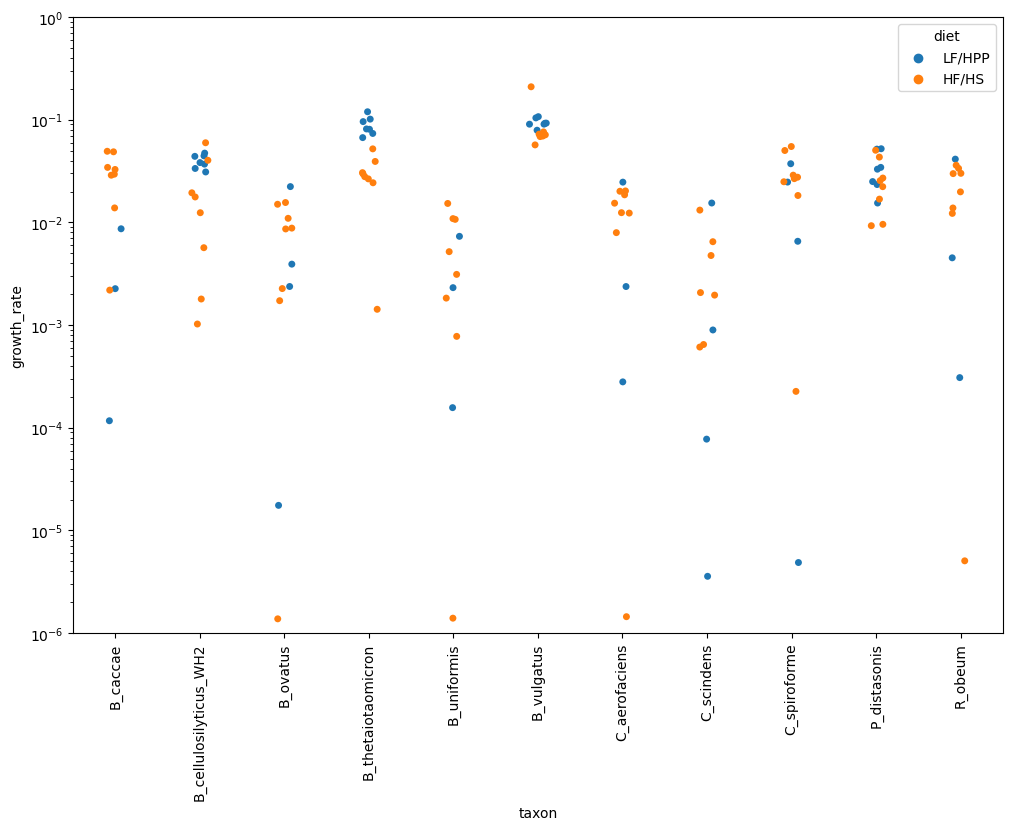

In [4]:
plt.figure(figsize=(12,8))
sns.stripplot(x='taxon', y='growth_rate', hue='diet', data=growth)
plt.xticks(rotation=90)
plt.yscale('log')
plt.ylim([1e-6,1])
plt.show()

## Exchange fluxes

In [5]:
annot = pfba_lf0.annotations
annot.index = annot.reaction
annot

,metabolite,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction
reaction,,,,,,,,,,
EX_12ppd_S(e),12ppd_S[e],"(S)-propane-1,2-diol",76.09442,3,0,HMDB06213,"InChI=1S/C3H8O2/c1-3(5)2-4/h3-5H,2H2,1H3/t3-/m...",C02917,NaN,EX_12ppd_S(e)
EX_2obut(e),2obut[e],2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e)
EX_4abut(e),4abut[e],4-Aminobutanoate,103.11976,4,1,HMDB00112,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",C00334,119.0,EX_4abut(e)
EX_4hbz(e),4hbz[e],4-hydroxybenzoate,137.11280,7,0,HMDB00500,"InChI=1S/C7H6O3/c8-6-3-1-5(2-4-6)7(9)10/h1-4,8...",C00156,NaN,EX_4hbz(e)
EX_MGlcn10(e),MGlcn10[e],mucin-type O-glycan No 10,NaN,44,4,NaN,NaN,NaN,NaN,EX_MGlcn10(e)
...,...,...,...,...,...,...,...,...,...,...
EX_mqn7_m,mqn7_m,Menaquinone 7,648.99916,46,0,NaN,NaN,C00828,4086.0,EX_mqn7_m
EX_n2_m,n2_m,Nitrogen,28.01340,0,2,NaN,NaN,NaN,NaN,EX_n2_m
EX_sbt_D_m,sbt_D_m,D-glucitol,182.17176,6,0,HMDB00247,InChI=1S/C6H14O6/c7-1-3(9)5(11)6(12)4(10)2-8/h...,C00794,5780.0,EX_sbt_D_m


### Imports

In [6]:
imports_lf0 = pfba_lf0.exchanges
imports_lf0 = imports_lf0[imports_lf0['direction'] == 'import'].copy()
imports_lf0['diet'] = 'LF/HPP'
imports_hf0 = pfba_hf0.exchanges
imports_hf0 = imports_hf0[imports_hf0['direction'] == 'import'].copy()
imports_hf0['diet'] = 'HF/HS'
imports = pd.concat([imports_lf0, imports_hf0], axis=0, ignore_index=True)
imports['flux'] = imports['flux'].abs() # note that the sign indicates the direction
imports

,taxon,sample_id,tolerance,reaction,flux,abundance,metabolite,direction,diet
0,medium,mouse_01,1.000000e-12,EX_pro_L_m,8.739835e-03,NaN,pro_L_m,import,LF/HPP
1,medium,mouse_01,1.000000e-12,EX_cbl1_m,3.177298e-12,NaN,cbl1_m,import,LF/HPP
2,medium,mouse_01,1.000000e-12,EX_h2s_m,2.194285e-03,NaN,h2s_m,import,LF/HPP
3,medium,mouse_01,1.000000e-12,EX_fol_m,5.452900e-05,NaN,fol_m,import,LF/HPP
4,medium,mouse_01,1.000000e-12,EX_q8_m,3.096500e-05,NaN,q8_m,import,LF/HPP
...,...,...,...,...,...,...,...,...,...
6016,C_aerofaciens,mouse_15,1.000000e-12,EX_fru(e),5.643532e-06,0.004272,fru[e],import,HF/HS
6017,C_aerofaciens,mouse_15,1.000000e-12,EX_mn2(e),2.893486e-08,0.004272,mn2[e],import,HF/HS
6018,C_aerofaciens,mouse_15,1.000000e-12,EX_glu_L(e),1.225167e-06,0.004272,glu_L[e],import,HF/HS
6019,C_aerofaciens,mouse_15,1.000000e-12,EX_nac(e),5.786972e-08,0.004272,nac[e],import,HF/HS


Me falta hacer esto, lo que ellos llamaban el metabolic space -> puede ser interesante

In [7]:
# import_pca = pd.pivot_table(imports, index='taxon', columns='reaction', values='flux')
# import_pca

In [8]:
imports_pivot = pd.pivot_table(                            # convert to a matrix of samples vs. metabolites
    imports,                                         # that contains the production rates
    index = ['diet', 'sample_id'],
    columns = 'reaction',
    values = 'flux'
)
imports_pivot = imports_pivot.T.fillna(0.0)
# imports_pivot.index = imports_pivot.index.map(annot.name.to_dict())
imports_pivot =  imports_pivot.apply(
    lambda xs: np.log(xs + 1e-7),
    axis=0)   
imports_pivot

diet                HF/HS                                                     \
sample_id        mouse_08  mouse_09   mouse_10  mouse_11  mouse_12  mouse_13   
reaction                                                                       
EX_26dap_M(e)   -8.981441 -8.759069  -9.433898 -8.247201 -8.507476 -9.010653   
EX_2obut(e)     -4.669216 -3.377665  -5.332568 -3.056272 -4.785227 -4.021961   
EX_7ocholate(e) -1.641314 -1.851724 -16.118096 -1.404128 -1.412811 -1.449869   
EX_acgam(e)     -4.938998 -4.416073  -5.810285 -4.121860 -4.885994 -4.564595   
EX_acnam(e)     -6.143127 -6.308591  -6.656653 -5.589001 -5.935605 -6.048903   
...                   ...       ...        ...       ...       ...       ...   
EX_val_L(e)     -4.593014 -4.849142  -4.740433 -4.628712 -4.676050 -4.662175   
EX_val_L_m      -4.511978 -4.618785  -4.296345 -4.623463 -4.683109 -4.793917   
EX_xan(e)       -5.023206 -5.874831  -5.133665 -5.101143 -5.055459 -4.950296   
EX_zn2(e)       -8.558828 -8.851130  -8.869932 -8.548772 -8.626171 -8.552999   
EX_zn2_m        -8.515987 -8.517759  -8.515529 -8.522506 -8.517436 -8.516477   

diet                                      LF/HPP                        \
sample_id         mouse_14   mouse_15   mouse_01   mouse_02   mouse_03   
reaction                                                                 
EX_26dap_M(e)    -9.825641 -16.049206 -16.118096 -12.541464 -10.115954   
EX_2obut(e)      -6.927345  -5.864071  -3.307426  -4.863473  -4.296710   
EX_7ocholate(e) -16.118096 -16.118096 -16.118096  -5.689671  -3.556106   
EX_acgam(e)      -6.627687 -13.715927 -16.118096  -9.170427  -5.883511   
EX_acnam(e)      -7.591262  -7.642392  -5.254545  -6.795294  -6.577813   
...                    ...        ...        ...        ...        ...   
EX_val_L(e)      -4.603774  -5.326667  -3.551486  -4.589103  -4.431194   
EX_val_L_m       -3.825670  -4.835824  -4.212410  -4.212455  -4.215778   
EX_xan(e)        -5.203151 -10.587408 -16.118096  -6.538130  -5.210394   
EX_zn2(e)        -9.090686  -9.624691  -8.150514  -9.280953  -8.934617   
EX_zn2_m         -8.516324  -8.515498  -8.515495  -8.515514  -8.515675   

diet                                                        
sample_id        mouse_04   mouse_05   mouse_06   mouse_07  
reaction                                                    
EX_26dap_M(e)   -8.349597 -16.118096 -15.657008 -16.118096  
EX_2obut(e)     -3.715846  -3.727512  -3.633749  -4.319070  
EX_7ocholate(e) -1.216857 -16.118096 -16.118096 -16.118096  
EX_acgam(e)     -4.801481 -16.118096 -16.118096 -16.118096  
EX_acnam(e)     -5.346353  -6.471992  -6.683238  -6.057264  
...                   ...        ...        ...        ...  
EX_val_L(e)     -4.260826  -3.857089  -4.023124  -4.038079  
EX_val_L_m      -4.225567  -4.212410  -4.212411  -4.212407  
EX_xan(e)       -4.798903 -16.118096 -13.654178 -16.118096  
EX_zn2(e)       -8.376470  -8.364585  -8.737135  -8.569062  
EX_zn2_m        -8.515573  -8.515495  -8.515495  -8.515495  

[163 rows x 15 columns]

In [9]:
imports_pivot_mean = imports_pivot.reindex(imports_pivot.mean(axis=1).sort_values(ascending=False).index).head(50)
imports_pivot_var = imports_pivot.reindex(imports_pivot.var(axis=1).sort_values(ascending=False).index).head(50)

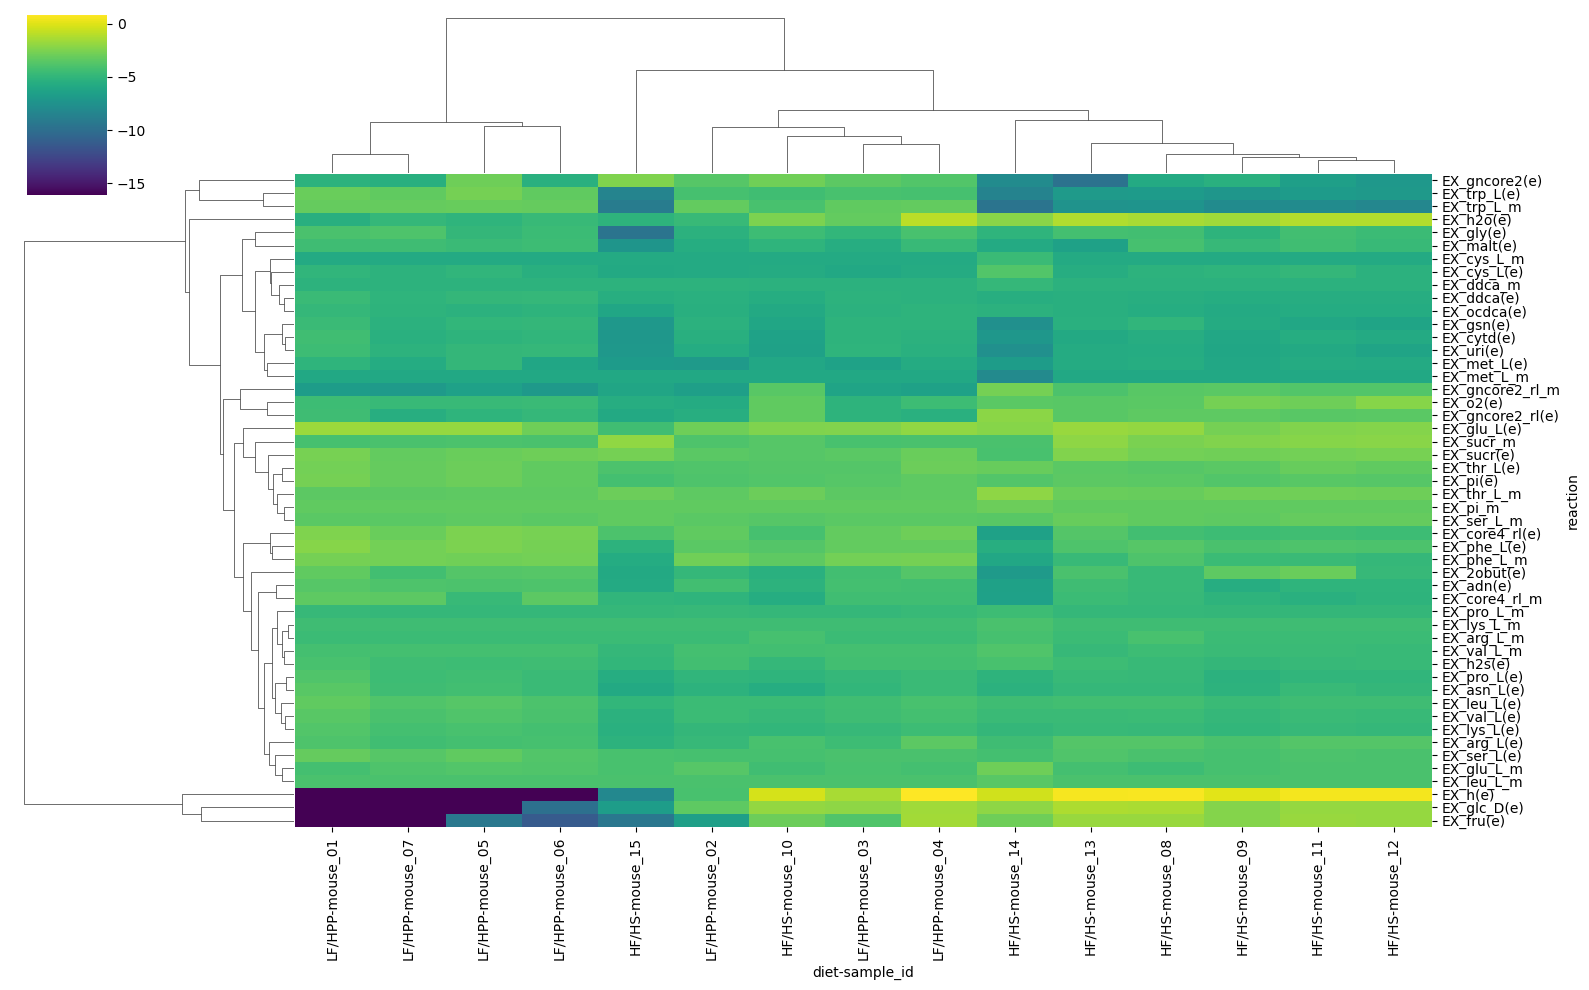

In [10]:
sns.clustermap(
    imports_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

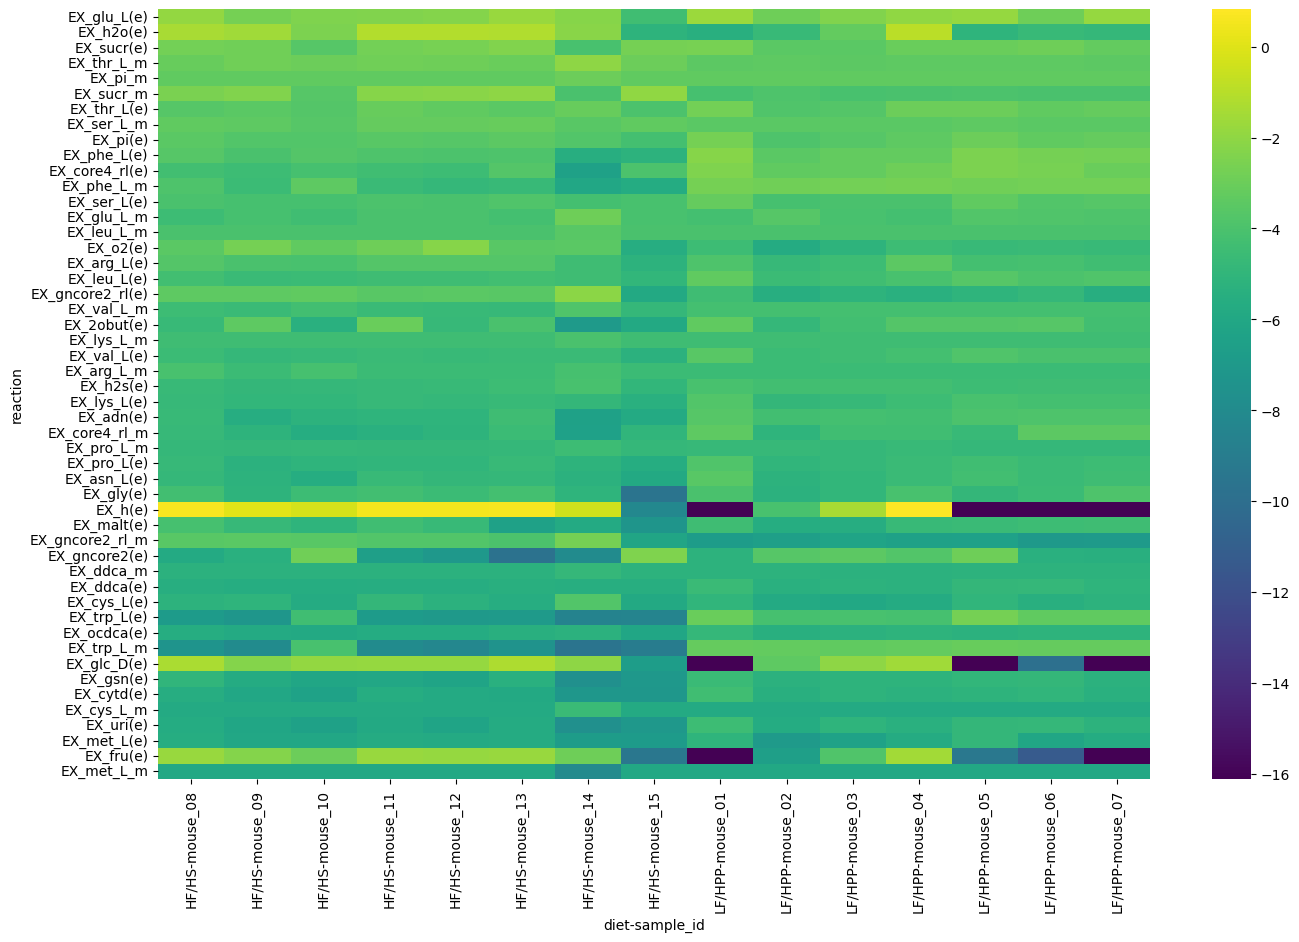

In [11]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    imports_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

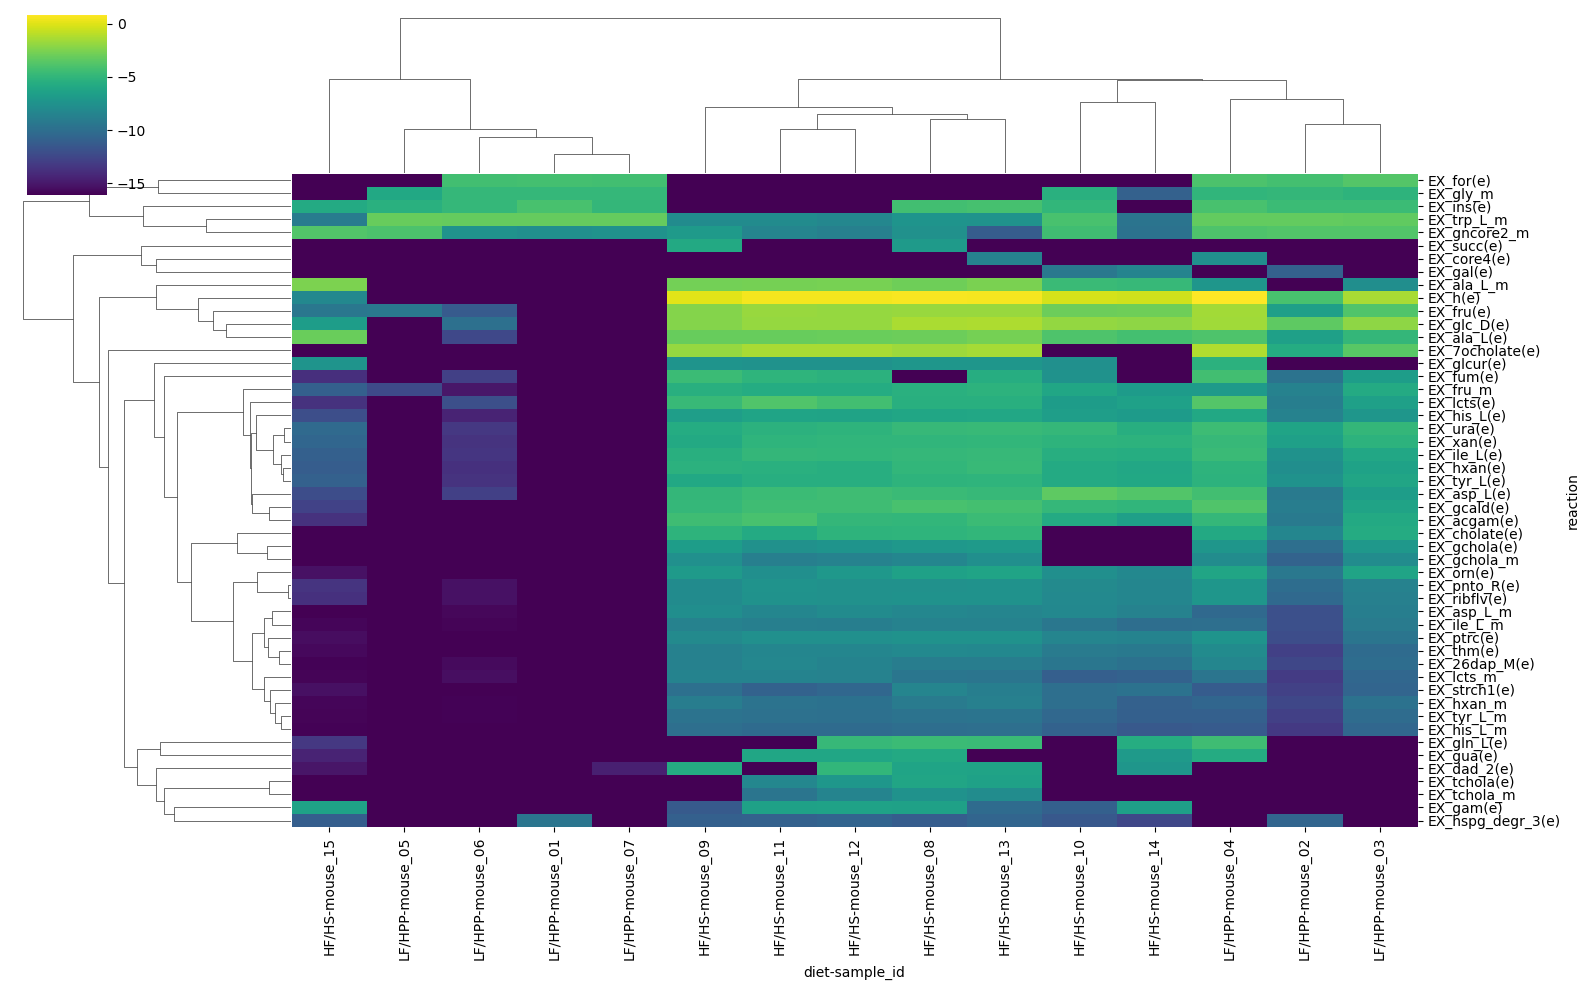

In [12]:
sns.clustermap(
    imports_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

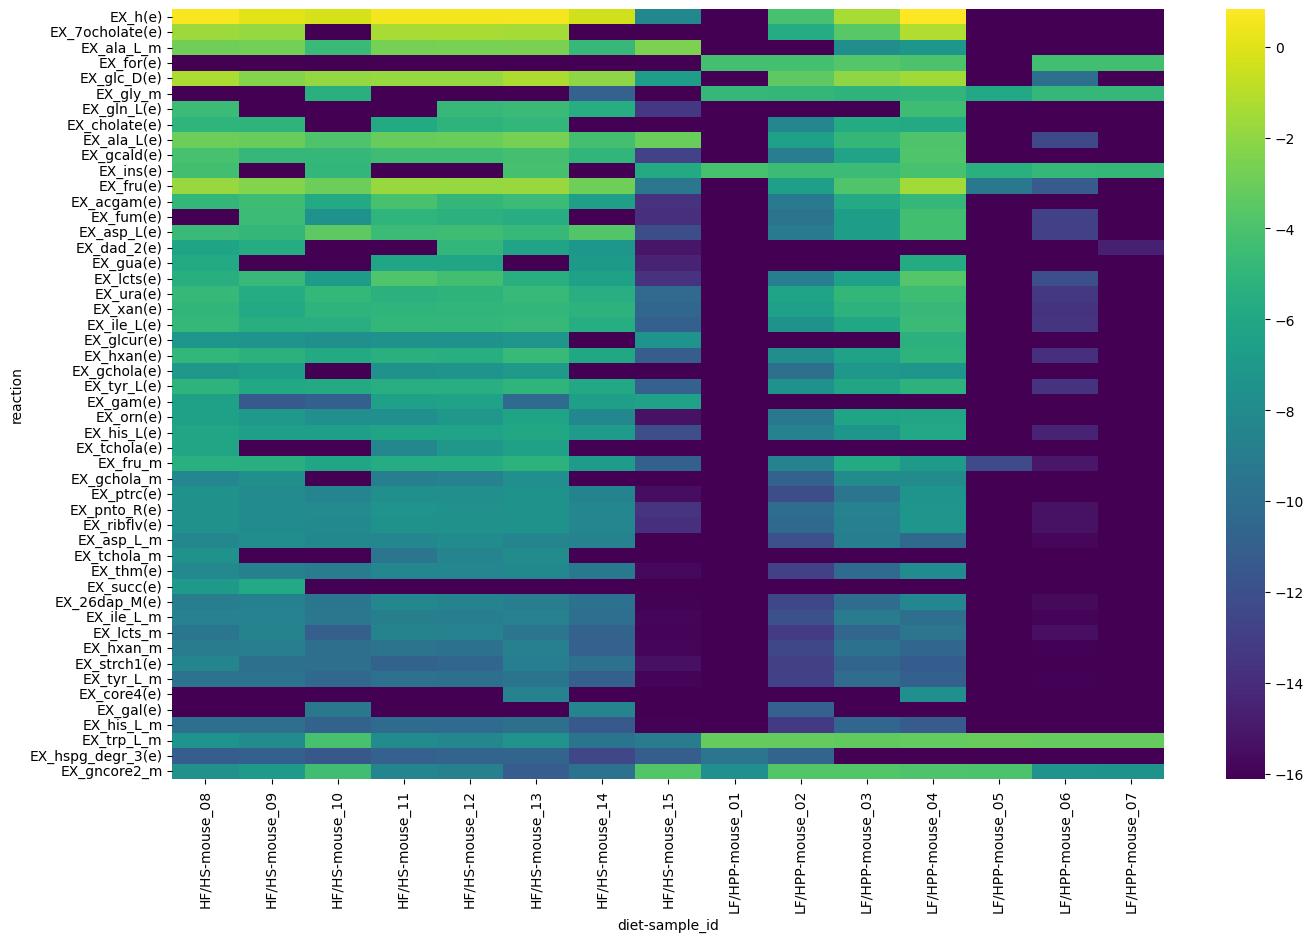

In [13]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    imports_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

### Exports

In [14]:
exports_lf0 = pfba_lf0.exchanges
exports_lf0 = exports_lf0[exports_lf0['direction'] == 'export'].copy()
exports_lf0['diet'] = 'LF/HPP'
exports_hf0 = pfba_hf0.exchanges
exports_hf0 = exports_hf0[exports_hf0['direction'] == 'export'].copy()
exports_hf0['diet'] = 'HF/HS'
exports = pd.concat([exports_lf0, exports_hf0], axis=0, ignore_index=True)
exports

,taxon,sample_id,tolerance,reaction,flux,abundance,metabolite,direction,diet
0,medium,mouse_01,1.000000e-12,EX_pac_m,0.061069,NaN,pac_m,export,LF/HPP
1,medium,mouse_01,1.000000e-12,EX_h2o_m,0.235297,NaN,h2o_m,export,LF/HPP
2,medium,mouse_01,1.000000e-12,EX_h_m,0.214187,NaN,h_m,export,LF/HPP
3,medium,mouse_01,1.000000e-12,EX_acgal_m,0.021505,NaN,acgal_m,export,LF/HPP
4,medium,mouse_01,1.000000e-12,EX_indole_m,0.039636,NaN,indole_m,export,LF/HPP
...,...,...,...,...,...,...,...,...,...
1792,C_aerofaciens,mouse_15,1.000000e-12,EX_orn(e),0.000007,0.004272,orn[e],export,HF/HS
1793,C_aerofaciens,mouse_15,1.000000e-12,EX_xan(e),0.000002,0.004272,xan[e],export,HF/HS
1794,C_aerofaciens,mouse_15,1.000000e-12,EX_ac(e),0.000021,0.004272,ac[e],export,HF/HS
1795,C_aerofaciens,mouse_15,1.000000e-12,EX_co2(e),0.000018,0.004272,co2[e],export,HF/HS


In [15]:
exports_pivot = pd.pivot_table(                            # convert to a matrix of samples vs. metabolites
    exports,                                         # that contains the production rates
    index = ['diet', 'sample_id'],
    columns = 'reaction',
    values = 'flux'
)
exports_pivot = exports_pivot.T.fillna(0.0)
# exports_pivot.index = exports_pivot.index.map(annot.name.to_dict())
exports_pivot =  exports_pivot.apply(
    lambda xs: np.log(xs + 1e-7),
    axis=0)
exports_pivot

diet                 HF/HS                                              \
sample_id         mouse_08   mouse_09   mouse_10   mouse_11   mouse_12   
reaction                                                                 
EX_26dap_M(e)   -10.609522 -10.101823 -12.543450 -10.001213  -9.806436   
EX_2obut(e)      -4.285396  -5.146544  -5.475123  -4.597178  -5.651237   
EX_4abut(e)     -16.118096 -16.118096 -16.118096 -16.118096 -16.118096   
EX_4abut_m      -16.118096 -16.118096 -16.118096 -16.118096 -16.118096   
EX_7ocholate(e)  -5.107573  -5.138756 -16.118096  -5.834487  -5.146879   
...                    ...        ...        ...        ...        ...   
EX_uchol_m       -7.114034  -7.673569 -16.118096  -8.448386  -7.887468   
EX_ura(e)        -6.018549  -5.877607  -9.100008  -7.984976  -5.098885   
EX_uri(e)        -5.218914  -5.901081  -5.730628  -6.457904  -6.624433   
EX_val_L(e)      -1.853827  -2.862907  -2.485339  -2.452816  -2.407131   
EX_xan(e)        -4.621847  -4.731517  -7.323295  -6.746712  -7.091742   

diet                                                 LF/HPP             \
sample_id         mouse_13   mouse_14   mouse_15   mouse_01   mouse_02   
reaction                                                                 
EX_26dap_M(e)   -10.353948 -11.432818 -16.112788 -16.118096 -13.244086   
EX_2obut(e)      -4.957025  -6.877952  -5.806736  -4.234424  -5.398976   
EX_4abut(e)     -16.118096 -16.118096  -6.659043  -8.012378 -16.118096   
EX_4abut_m      -16.118096 -16.118096  -9.517045 -11.354121 -16.118096   
EX_7ocholate(e)  -4.936049 -16.118096 -16.118096 -16.118096  -8.324765   
...                    ...        ...        ...        ...        ...   
EX_uchol_m       -7.147850 -16.118096 -16.118096 -16.118096 -10.778948   
EX_ura(e)        -6.002811  -6.886112 -14.718719 -16.118096 -10.986778   
EX_uri(e)        -6.183433  -7.610727  -6.901292  -6.080290  -5.763783   
EX_val_L(e)      -1.764619  -2.554825  -7.255924 -16.118096  -3.889852   
EX_xan(e)        -4.354639  -7.121235 -12.891376 -16.118096 -10.493538   

diet                                                                    
sample_id         mouse_03   mouse_04   mouse_05   mouse_06   mouse_07  
reaction                                                                
EX_26dap_M(e)   -10.284253  -9.079602 -16.118096 -16.050569 -16.118096  
EX_2obut(e)      -4.553509  -4.037097  -4.883580  -4.888009  -4.832829  
EX_4abut(e)     -16.118096 -16.118096  -7.197609  -7.285214  -7.424589  
EX_4abut_m      -16.118096 -16.118096 -10.165037 -10.619262 -10.758913  
EX_7ocholate(e)  -5.726582  -5.866393 -16.118096 -16.118096 -16.118096  
...                    ...        ...        ...        ...        ...  
EX_uchol_m       -7.938251  -7.970937 -16.118096 -16.118096 -16.118096  
EX_ura(e)        -9.381547  -8.659217 -16.118096 -15.922854 -16.118096  
EX_uri(e)        -5.728680  -5.829544  -5.217032  -5.298942  -5.308323  
EX_val_L(e)      -2.562069  -2.150572 -16.118096 -11.074791 -16.118096  
EX_xan(e)        -9.311253  -8.014818 -16.118096 -16.095007 -16.118096  

[103 rows x 15 columns]

In [16]:
exports_pivot_mean = exports_pivot.reindex(exports_pivot.mean(axis=1).sort_values(ascending=False).index).head(50)
exports_pivot_var = exports_pivot.reindex(exports_pivot.var(axis=1).sort_values(ascending=False).index).head(50)

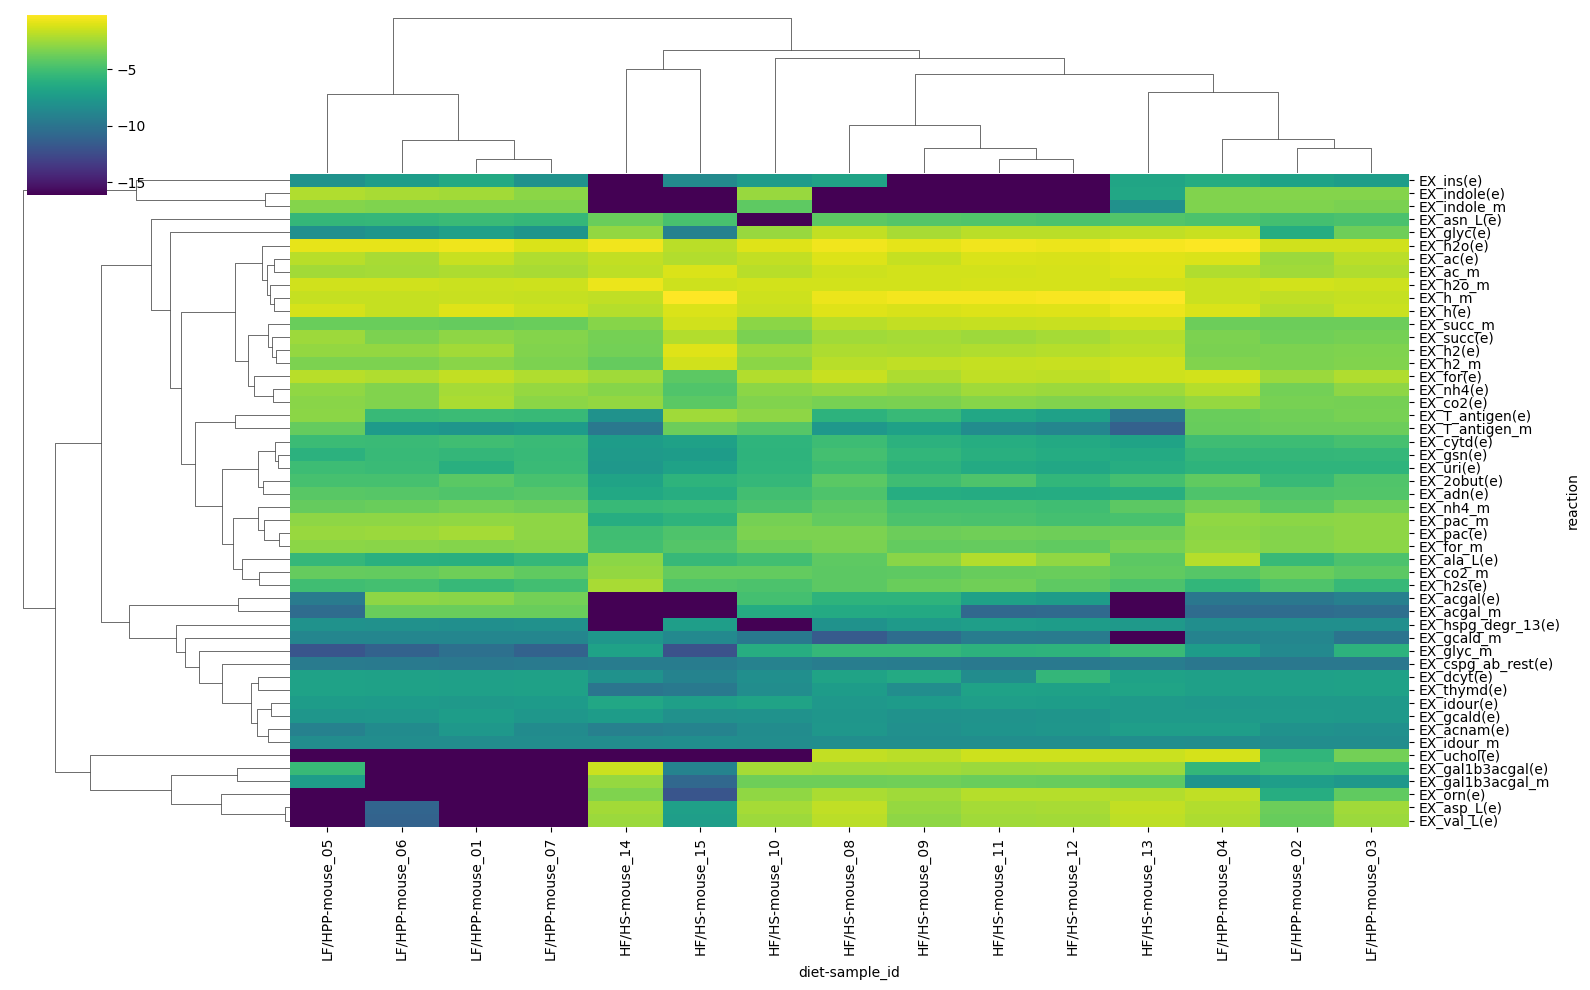

In [17]:
sns.clustermap(
    exports_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

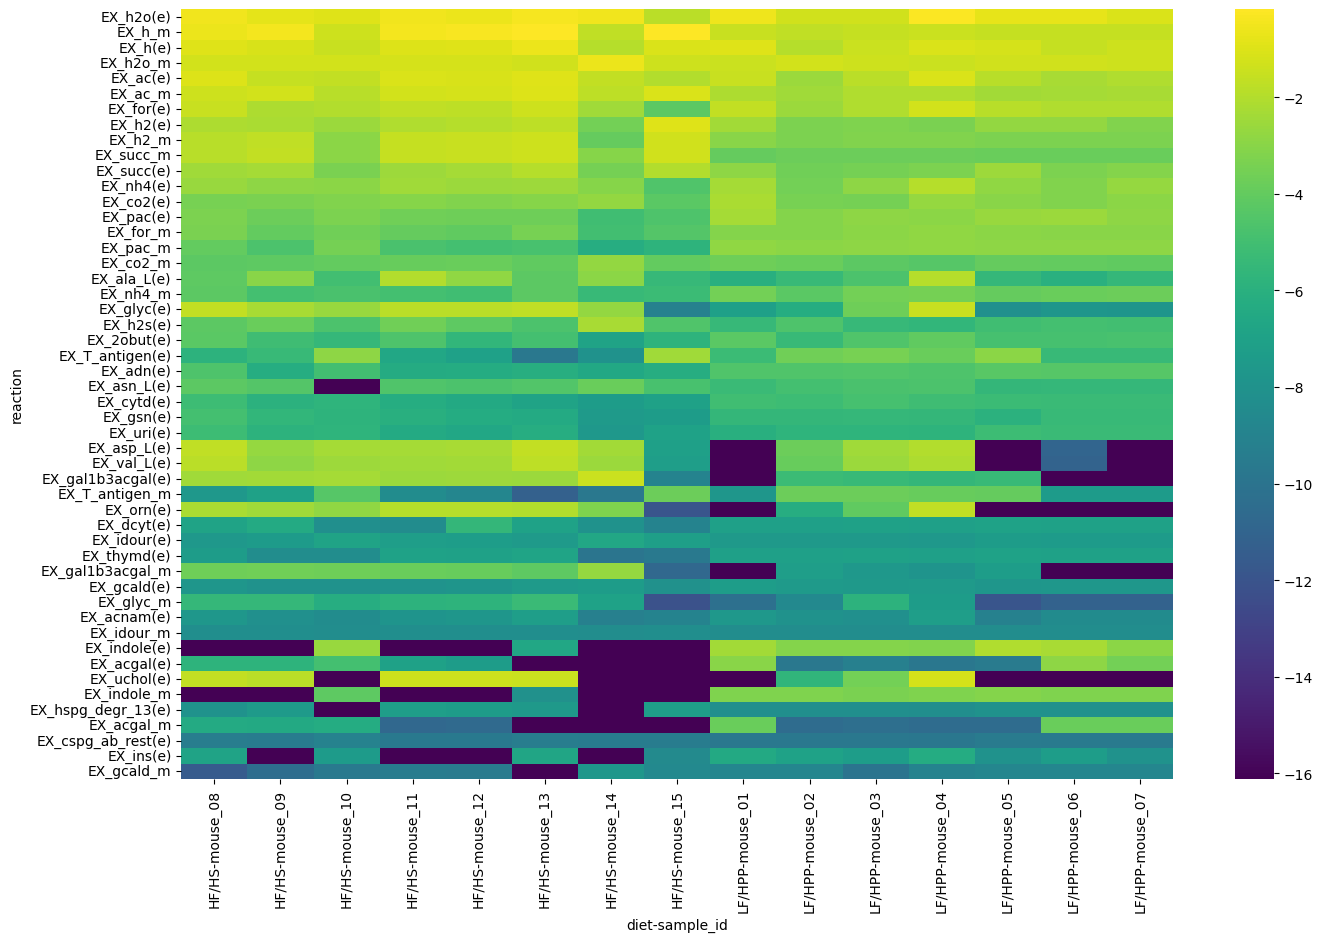

In [18]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    exports_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

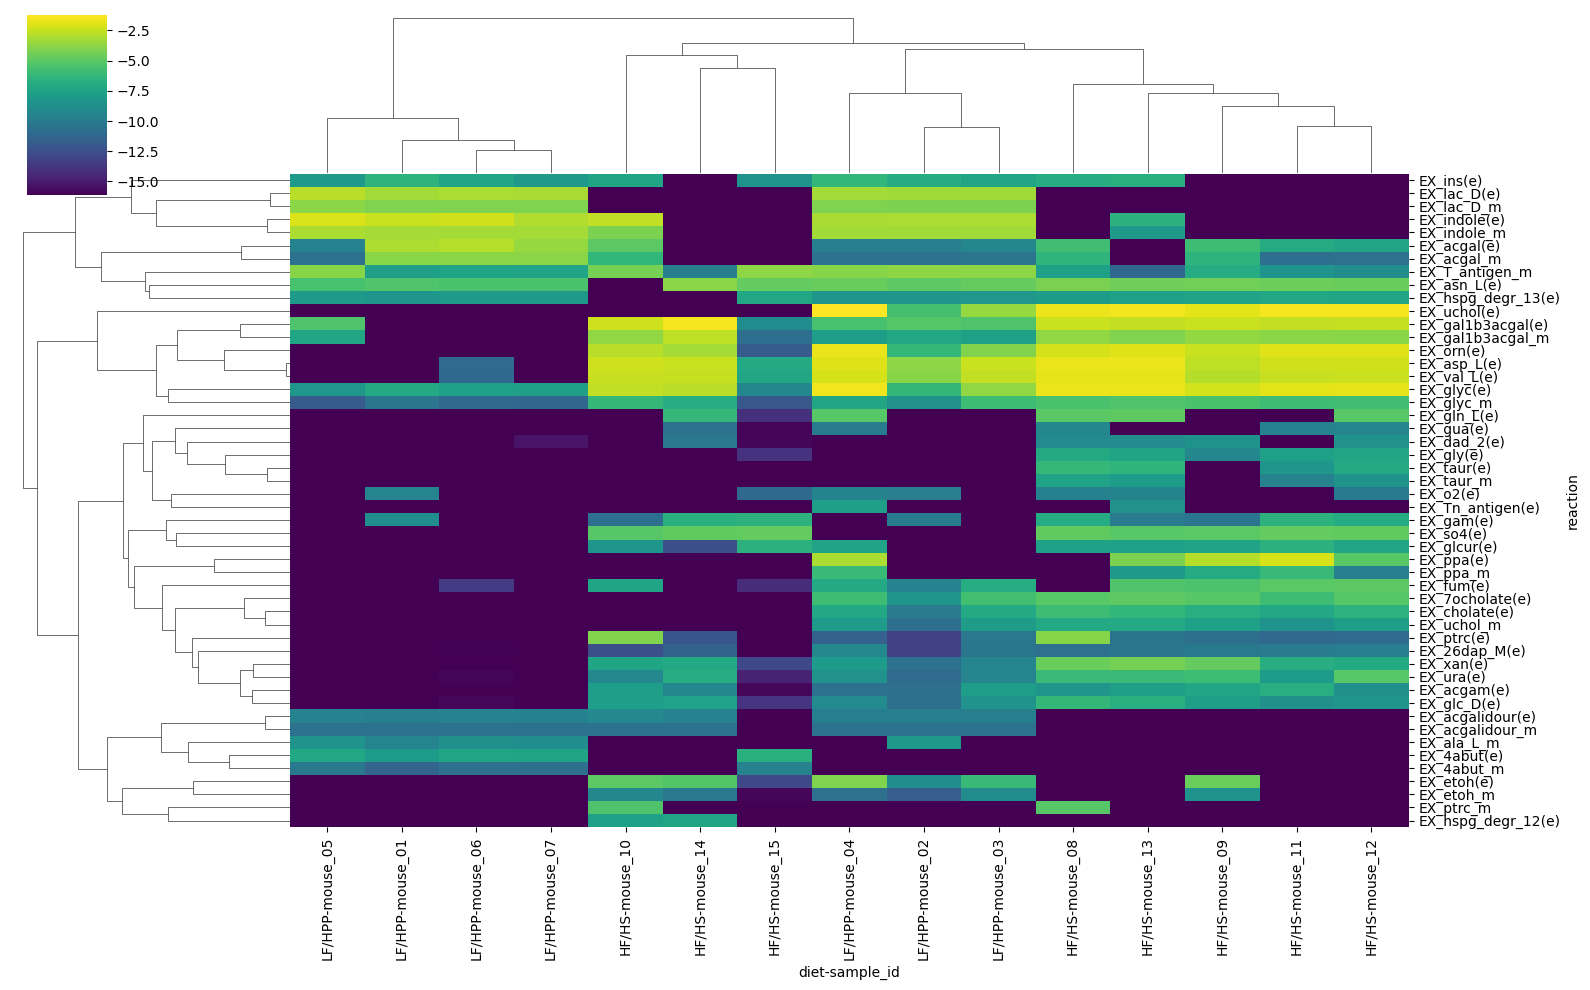

In [19]:
sns.clustermap(
    exports_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

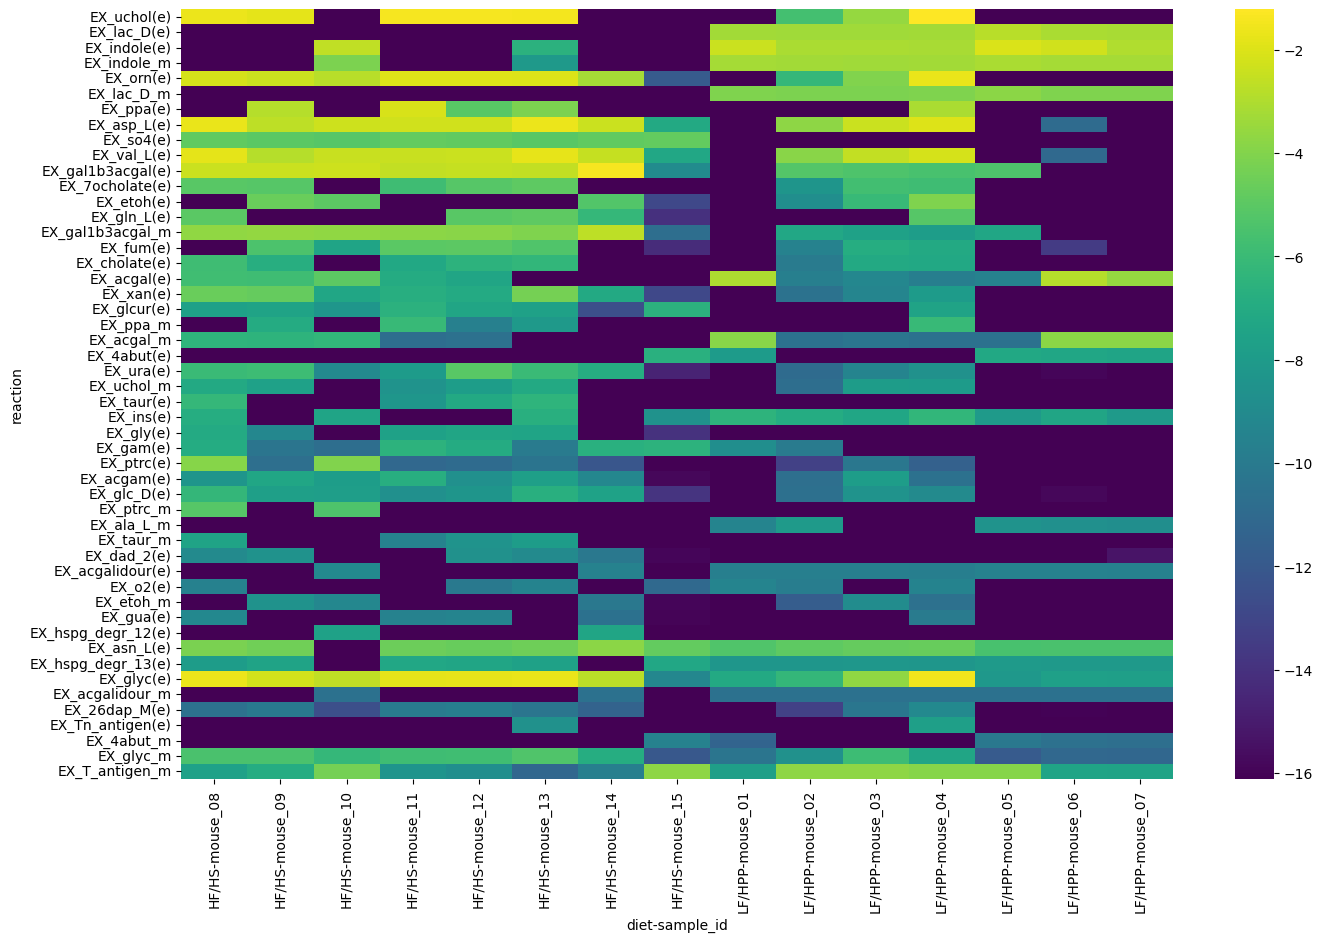

In [20]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    exports_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

## Consumption and production rates

### Consumption

In [21]:
consumption_lf0 = consumption_rates(pfba_lf0)
consumption_lf0['diet'] = 'LF/HPP'
consumption_hf0 = consumption_rates(pfba_hf0)
consumption_hf0['diet'] = 'HF/HS'
consumption = pd.concat([consumption_lf0, consumption_hf0], axis=0, ignore_index=True)
consumption

,sample_id,metabolite,flux,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction,diet
0,mouse_01,2obut[e],6.433559e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
1,mouse_02,2obut[e],2.018134e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
2,mouse_03,2obut[e],4.562885e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
3,mouse_04,2obut[e],8.136805e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
4,mouse_05,2obut[e],2.717955e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1158,mouse_14,nh4[e],4.464364e-05,Ammonium,18.03846,0,1,HMDB00051,InChI=1S/H3N/h1H3/p+1,C00014,223.0,EX_nh4(e),HF/HS
1159,mouse_15,chtbs[e],2.330003e-09,"N,N-diacetylchitobiose",424.40032,16,2,NaN,NaN,NaN,NaN,EX_chtbs(e),HF/HS
1160,mouse_15,din[e],2.147291e-10,Deoxyinosine,252.22668,10,4,HMDB00071,InChI=1S/C10H12N4O4/c15-2-6-5(16)1-7(18-6)14-4...,C05512,65058.0,EX_din(e),HF/HS
1161,mouse_15,melib[e],7.524915e-09,Melibiose,342.29648,12,0,NaN,NaN,NaN,NaN,EX_melib(e),HF/HS


In [22]:
consumption_pivot = pd.pivot_table(consumption, index=['diet', 'sample_id'], columns='name', values='flux')
consumption_pivot = consumption_pivot.T.fillna(0)
consumption_pivot = consumption_pivot.apply(lambda x: np.log10(x + 1e-9), axis=0)
consumption_pivot

diet                                                   HF/HS            \
sample_id                                           mouse_08  mouse_09   
name                                                                     
(R)-Pantothenate                                   -5.361979 -5.251366   
2-Oxobutanoate                                     -2.415183 -2.784572   
2-deoxyadenosine                                   -4.472083 -4.259305   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate     -3.089638 -3.332681   
Adenosine                                          -2.576675 -3.259909   
...                                                      ...       ...   
starch, structure 1 (1,6-{7[1,4-Glc], 4[1,4-Glc]}) -4.446335 -5.022297   
sulfate                                            -2.823413 -2.813742   
taurocholate                                       -3.239936 -9.000000   
tetradecanoate (n-C14:0)                           -2.989703 -2.990226   
uracil                                             -4.391094 -4.222172   

diet                                                                    \
sample_id                                           mouse_10  mouse_11   
name                                                                     
(R)-Pantothenate                                   -5.842663 -5.241402   
2-Oxobutanoate                                     -2.961657 -2.384112   
2-deoxyadenosine                                   -9.000000 -9.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate     -9.000000 -3.669288   
Adenosine                                          -2.752235 -2.909992   
...                                                      ...       ...   
starch, structure 1 (1,6-{7[1,4-Glc], 4[1,4-Glc]}) -5.006420 -5.110860   
sulfate                                            -2.836539 -2.812581   
taurocholate                                       -9.000000 -4.140367   
tetradecanoate (n-C14:0)                           -2.986096 -2.989039   
uracil                                             -5.773961 -5.495456   

diet                                                                    \
sample_id                                           mouse_12  mouse_13   
name                                                                     
(R)-Pantothenate                                   -5.338031 -5.385027   
2-Oxobutanoate                                     -2.841479 -2.653214   
2-deoxyadenosine                                   -4.145286 -4.439875   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate     -3.425598 -3.104326   
Adenosine                                          -2.964333 -2.893630   
...                                                      ...       ...   
starch, structure 1 (1,6-{7[1,4-Glc], 4[1,4-Glc]}) -4.960410 -4.519015   
sulfate                                            -2.810603 -2.809556   
taurocholate                                       -3.682584 -3.436270   
tetradecanoate (n-C14:0)                           -2.988449 -2.990268   
uracil                                             -4.116405 -4.377902   

diet                                                                    \
sample_id                                           mouse_14  mouse_15   
name                                                                     
(R)-Pantothenate                                   -5.980048 -8.691560   
2-Oxobutanoate                                     -3.442909 -3.096003   
2-deoxyadenosine                                   -4.956536 -8.159910   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate     -9.000000 -9.000000   
Adenosine                                          -3.401369 -3.258469   
...                                                      ...       ...   
starch, structure 1 (1,6-{7[1,4-Glc], 4[1,4-Glc]}) -4.989458 -7.471088   
sulfate                                            -2.806114 -2.806284   
taurocholate                                       -9.000000 -9.000000   
t

In [23]:
consumption_pivot_mean = consumption_pivot.reindex(consumption_pivot.mean(axis=1).sort_values(ascending=False).index).head(50)
consumption_pivot_var = consumption_pivot.reindex(consumption_pivot.var(axis=1).sort_values(ascending=False).index).head(50)

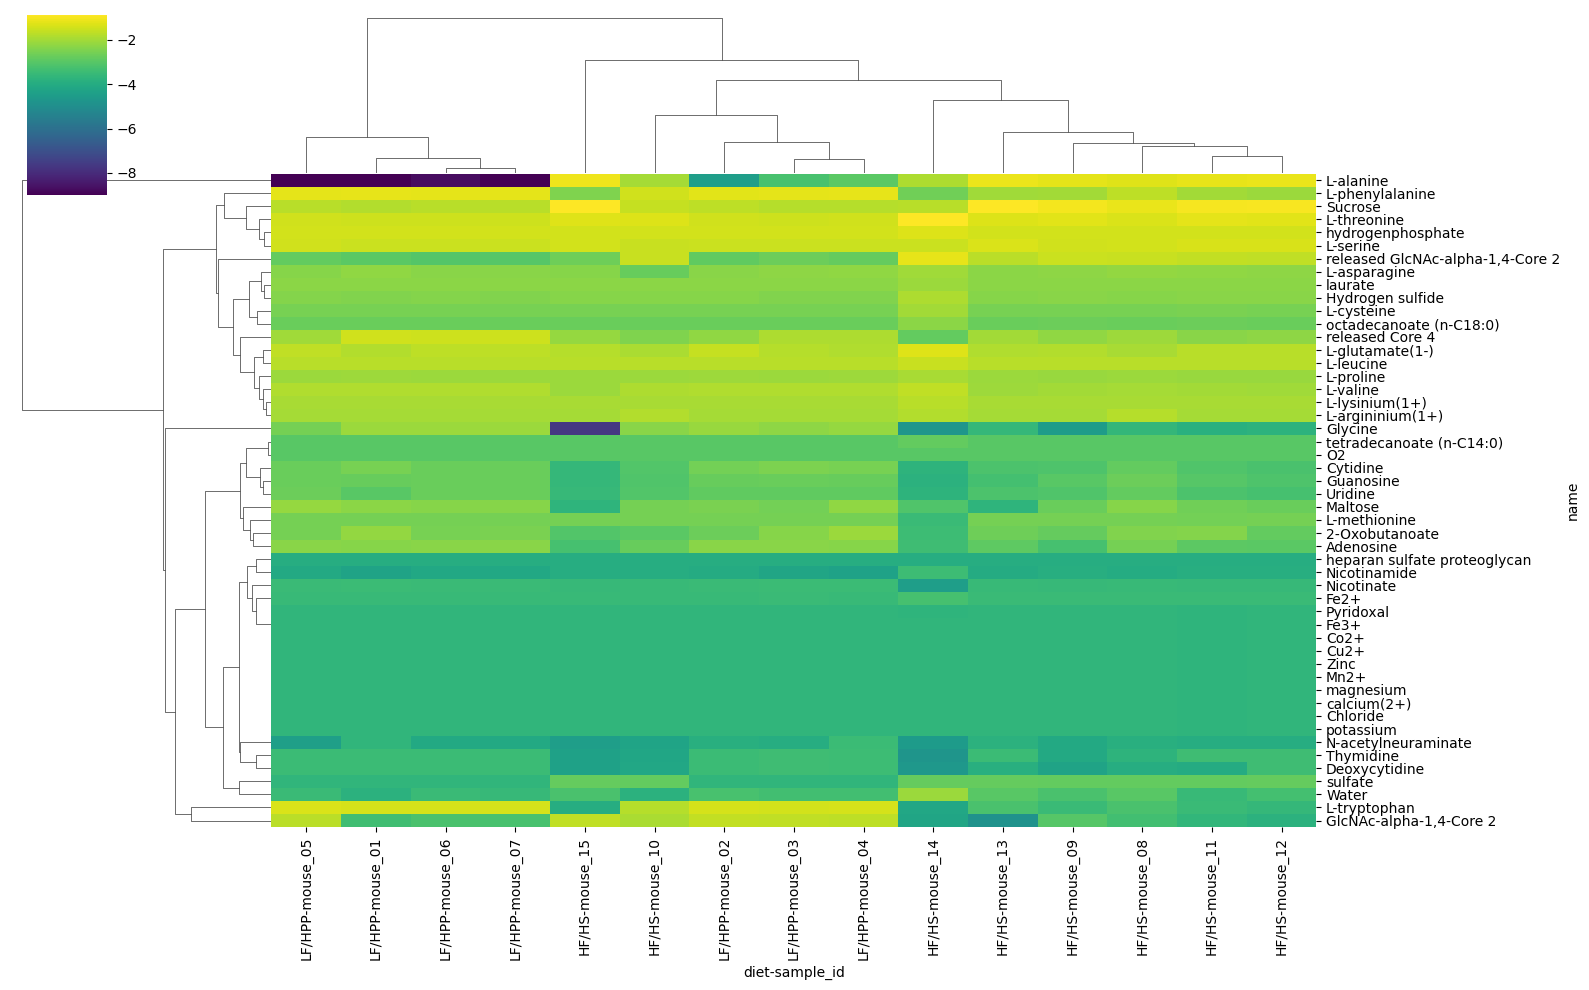

In [24]:
sns.clustermap(
    consumption_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

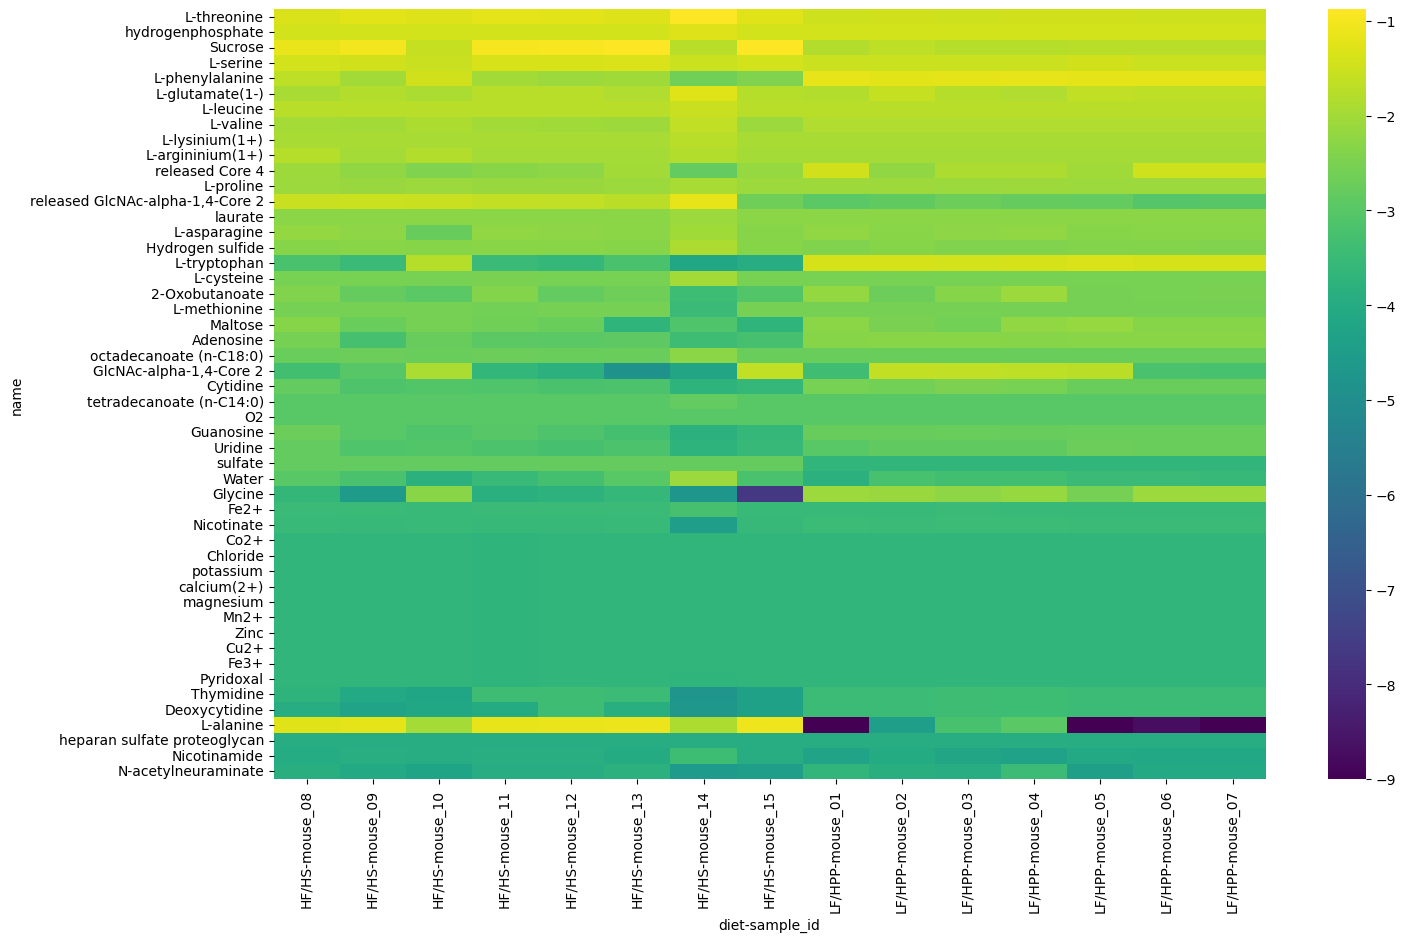

In [25]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    consumption_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

### Production

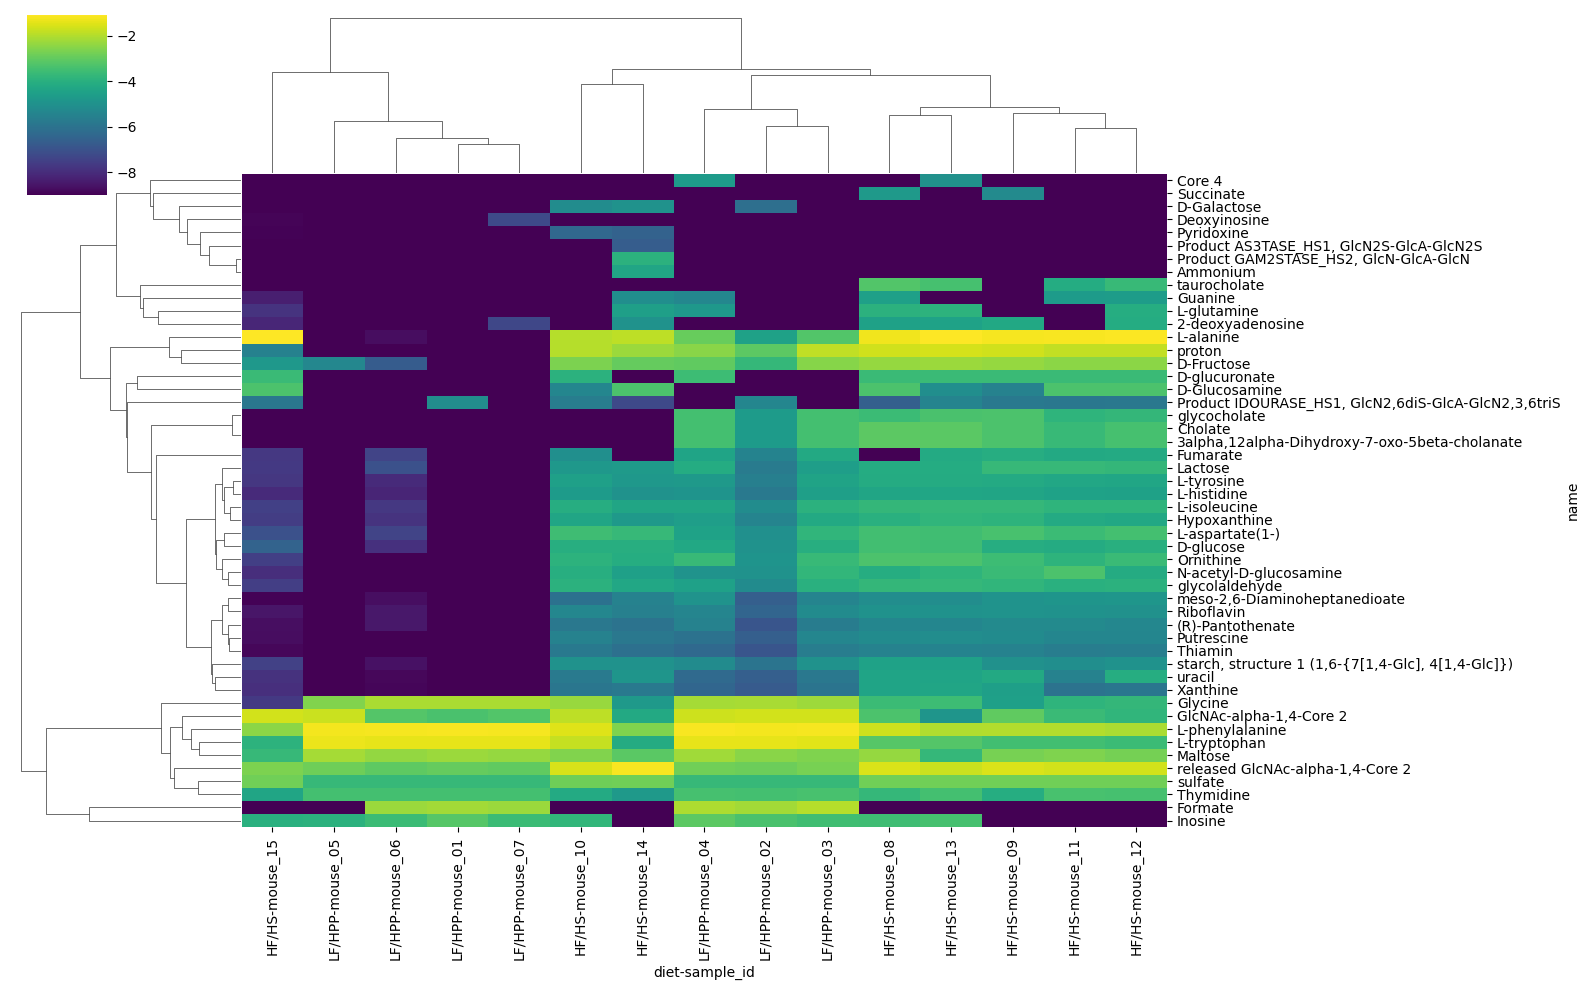

In [26]:
sns.clustermap(
    consumption_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

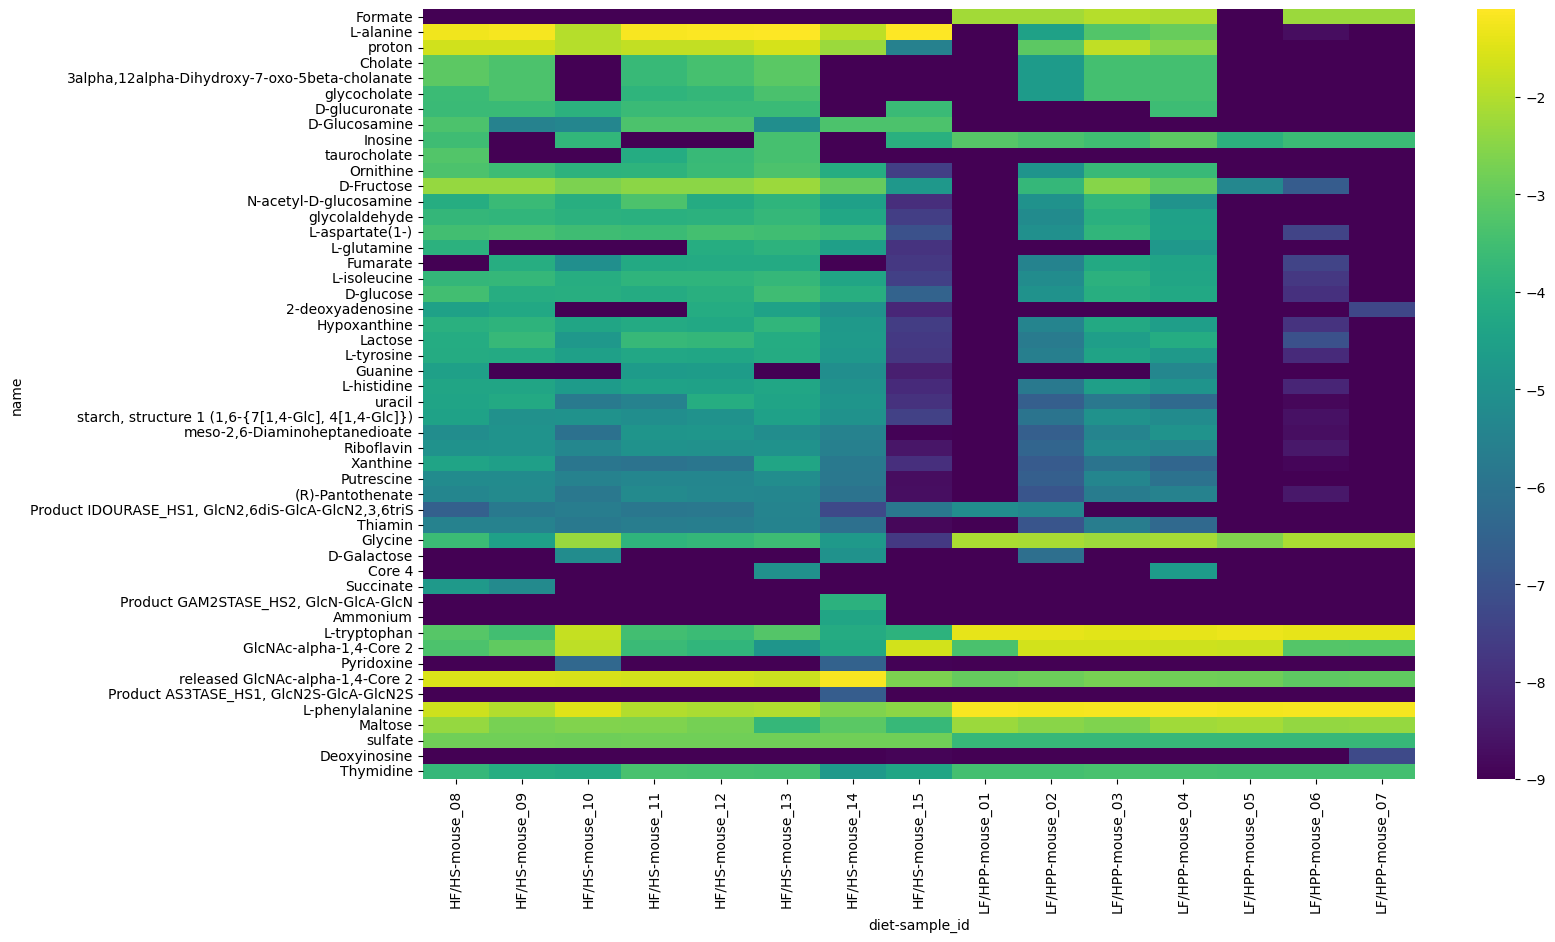

In [27]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    consumption_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

In [28]:
production_lf0 = production_rates(pfba_lf0)
production_lf0['diet'] = 'LF/HPP'
production_hf0 = production_rates(pfba_hf0)
production_hf0['diet'] = 'HF/HS'
production = pd.concat([production_lf0, production_hf0], axis=0, ignore_index=True)
production

,sample_id,metabolite,flux,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction,diet
0,mouse_01,2obut[e],6.433559e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
1,mouse_02,2obut[e],2.018134e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
2,mouse_03,2obut[e],4.562885e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
3,mouse_04,2obut[e],8.136805e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
4,mouse_05,2obut[e],2.717955e-03,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e),LF/HPP
...,...,...,...,...,...,...,...,...,...,...,...,...,...
690,mouse_15,4abut[e],7.348683e-05,4-Aminobutanoate,103.11976,4,1,HMDB00112,"InChI=1S/C4H9NO2/c5-3-1-2-4(6)7/h1-3,5H2,(H,6,7)",C00334,119.0,EX_4abut(e),HF/HS
691,mouse_15,chtbs[e],2.330003e-09,"N,N-diacetylchitobiose",424.40032,16,2,NaN,NaN,NaN,NaN,EX_chtbs(e),HF/HS
692,mouse_15,din[e],2.147291e-10,Deoxyinosine,252.22668,10,4,HMDB00071,InChI=1S/C10H12N4O4/c15-2-6-5(16)1-7(18-6)14-4...,C05512,65058.0,EX_din(e),HF/HS
693,mouse_15,leu_L[e],1.551681e-05,L-leucine,131.17292,6,1,HMDB00687,"InChI=1S/C6H13NO2/c1-4(2)3-5(7)6(8)9/h4-5H,3,7...",C00123,6106.0,EX_leu_L(e),HF/HS


In [29]:
production_pivot = pd.pivot_table(production, index=['diet', 'sample_id'], columns='name', values='flux')
production_pivot = production_pivot.T.fillna(0)
production_pivot = production_pivot.apply(lambda x: np.log10(x + 1e-9), axis=0)
production_pivot

diet                                               HF/HS                      \
sample_id                                       mouse_08  mouse_09  mouse_10   
name                                                                           
(R)-lactate                                    -9.000000 -9.000000 -9.000000   
2-Oxobutanoate                                 -2.415183 -2.784572 -2.961657   
2-deoxyadenosine                               -4.472083 -4.259305 -9.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate -3.089638 -3.332681 -9.000000   
4-Aminobutanoate                               -9.000000 -9.000000 -9.000000   
...                                                  ...       ...       ...   
phenylacetate                                  -1.743940 -2.049282 -1.511004   
propionate                                     -9.000000 -3.046246 -9.000000   
proton                                         -0.262319 -0.191904 -0.576002   
sulfate                                        -2.885565 -2.874425 -2.900746   
uracil                                         -4.391094 -4.222172 -5.773961   

diet                                                                          \
sample_id                                       mouse_11  mouse_12  mouse_13   
name                                                                           
(R)-lactate                                    -9.000000 -9.000000 -9.000000   
2-Oxobutanoate                                 -2.384112 -2.841479 -2.653214   
2-deoxyadenosine                               -9.000000 -4.145286 -4.439875   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate -3.669288 -3.425598 -3.104326   
4-Aminobutanoate                               -9.000000 -9.000000 -9.000000   
...                                                  ...       ...       ...   
phenylacetate                                  -2.064728 -2.143286 -2.095704   
propionate                                     -2.630915 -4.198387 -3.513373   
proton                                         -0.175905 -0.145315 -0.076562   
sulfate                                        -2.873090 -2.870817 -2.869615   
uracil                                         -5.495456 -4.116405 -4.377902   

diet                                                                  LF/HPP  \
sample_id                                       mouse_14  mouse_15  mouse_01   
name                                                                           
(R)-lactate                                    -9.000000 -9.000000 -1.778348   
2-Oxobutanoate                                 -3.442909 -3.096003 -2.191549   
2-deoxyadenosine                               -4.956536 -8.159910 -9.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate -9.000000 -9.000000 -9.000000   
4-Aminobutanoate                               -9.000000 -4.133785 -4.934716   
...                                                  ...       ...       ...   
phenylacetate                                  -2.674631 -2.519052 -1.214178   
propionate                                     -9.000000 -9.000000 -9.000000   
proton                                         -0.737518 -0.076074 -0.669207   
sulfate                                        -2.865664 -2.865859 -9.000000   
uracil                                         -4.881303 -7.882530 -9.000000   

diet                                                                          \
sample_id                                       mouse_02  mouse_03  mouse_04   
name                                                                           
(R)-lactate                                    -1.793702 -1.807331 -1.769537   
2-Oxobutanoate                                 -2.695050 -2.340760 -2.089546   
2-deoxyadenosine                               -9.000000 -9.000000 -9.000000   
3alpha,12alpha-Dihydroxy-7-oxo-5beta-cholanate -4.683306 -3.447659 -3.461858   
4-Aminobutanoate                               -9.000000 -9.000000 -9.000000 

In [30]:
production_pivot_mean = production_pivot.reindex(production_pivot.mean(axis=1).sort_values(ascending=False).index).head(50)
production_pivot_var = production_pivot.reindex(production_pivot.var(axis=1).sort_values(ascending=False).index).head(50)

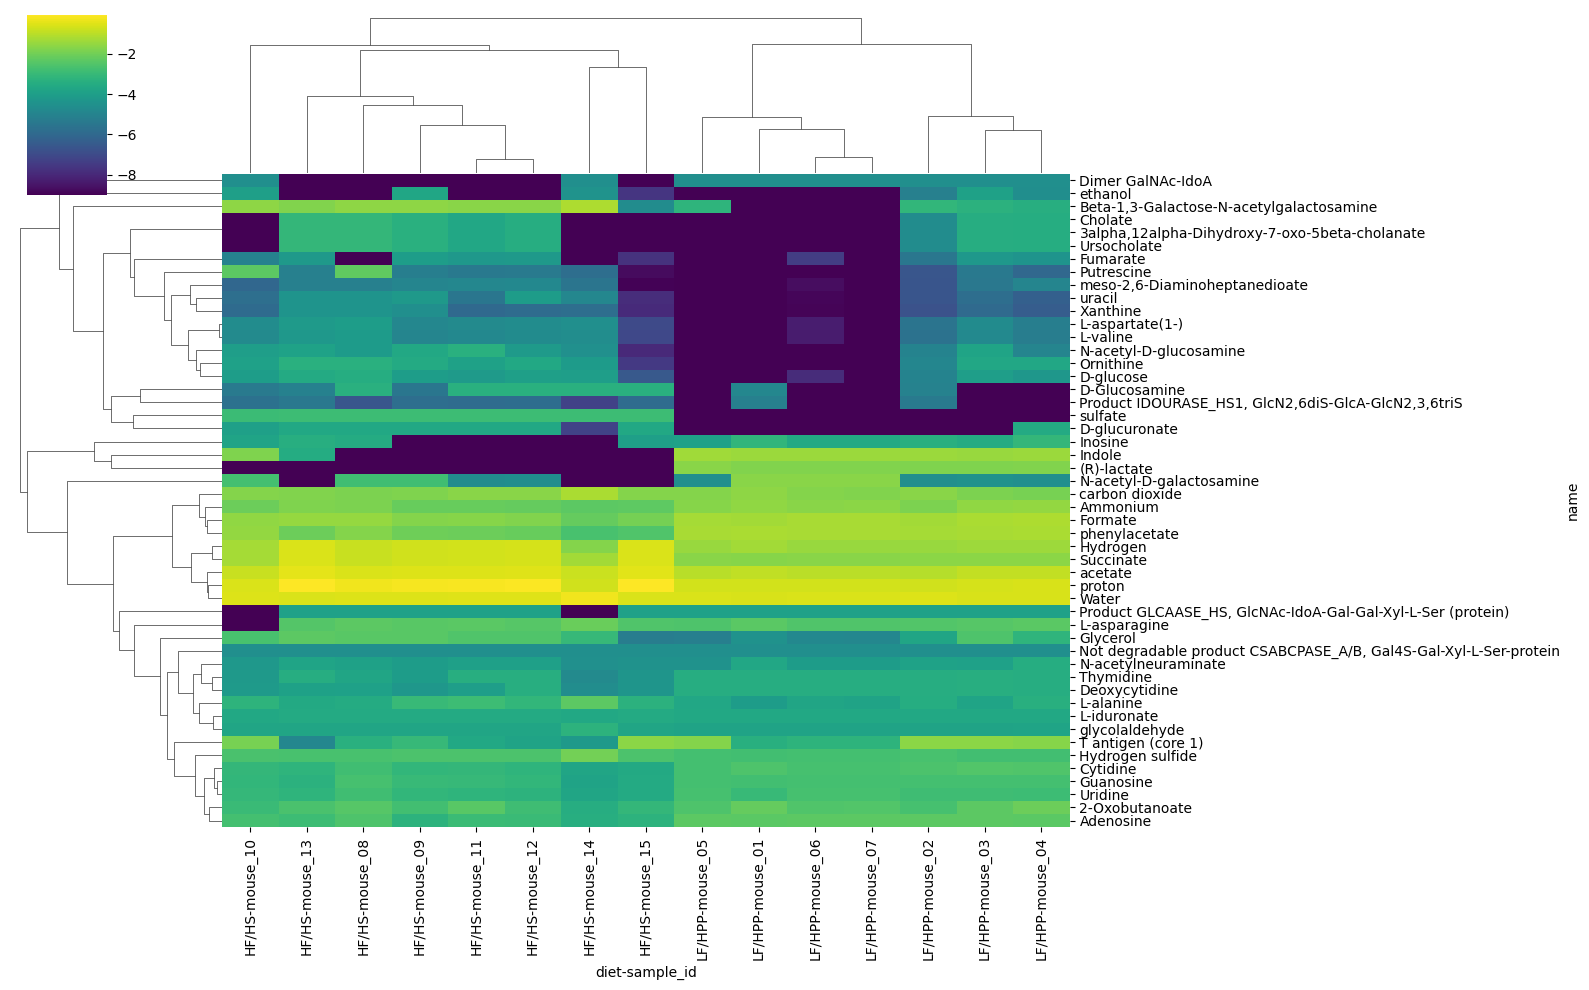

In [31]:
sns.clustermap(
    production_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

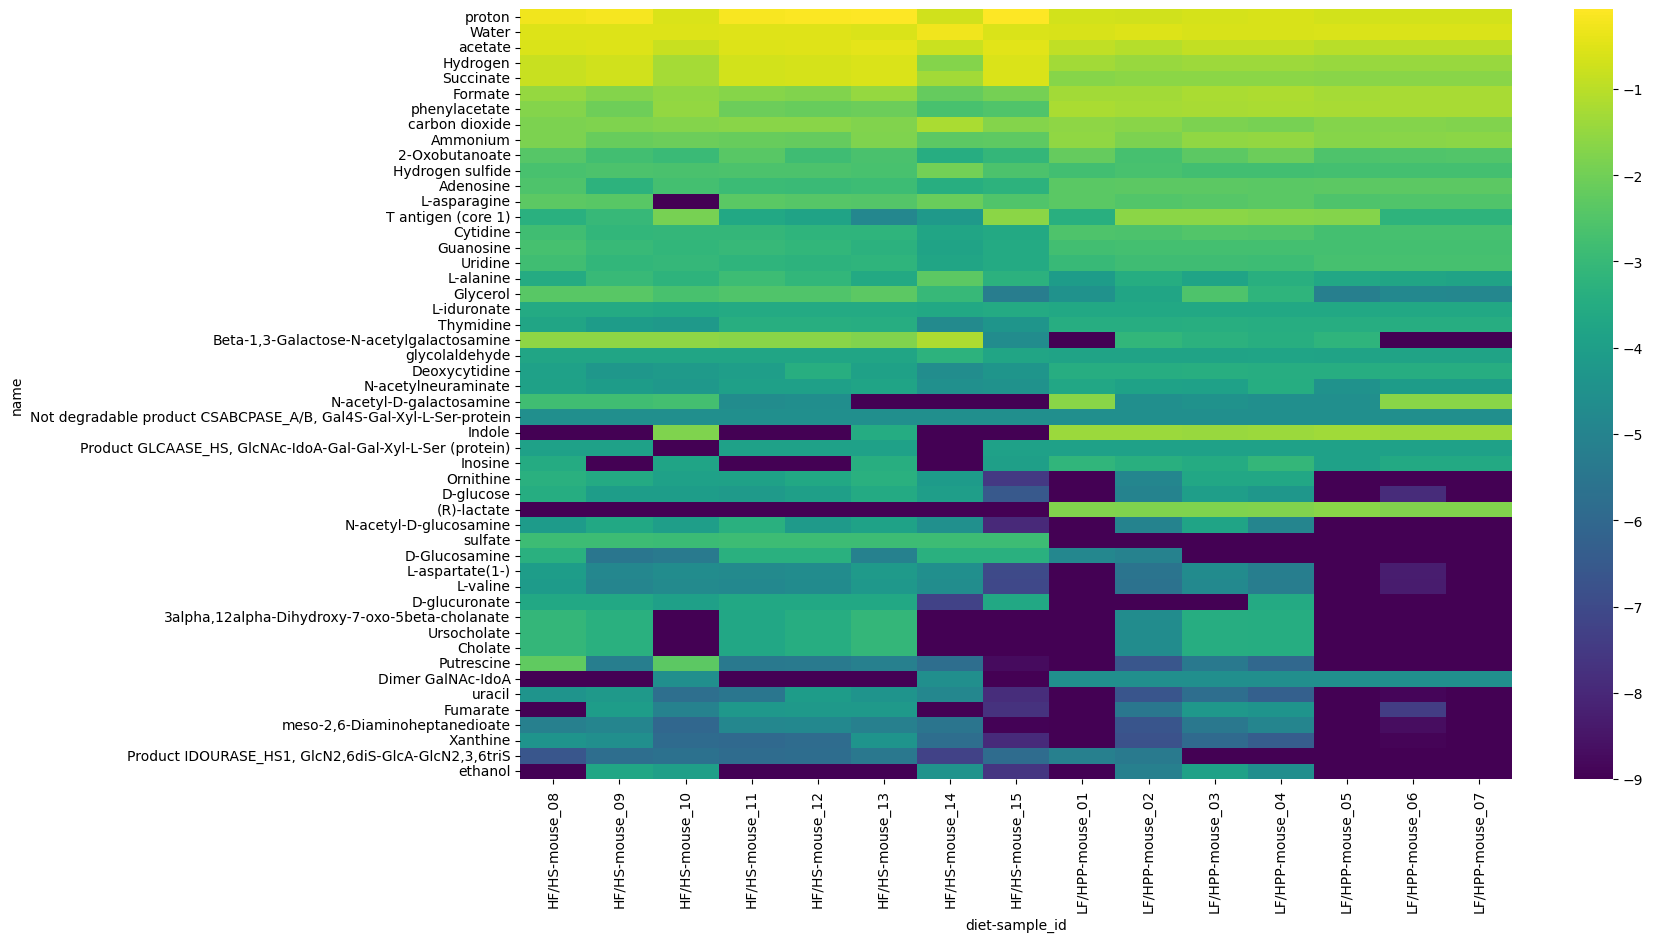

In [32]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    production_pivot_mean,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

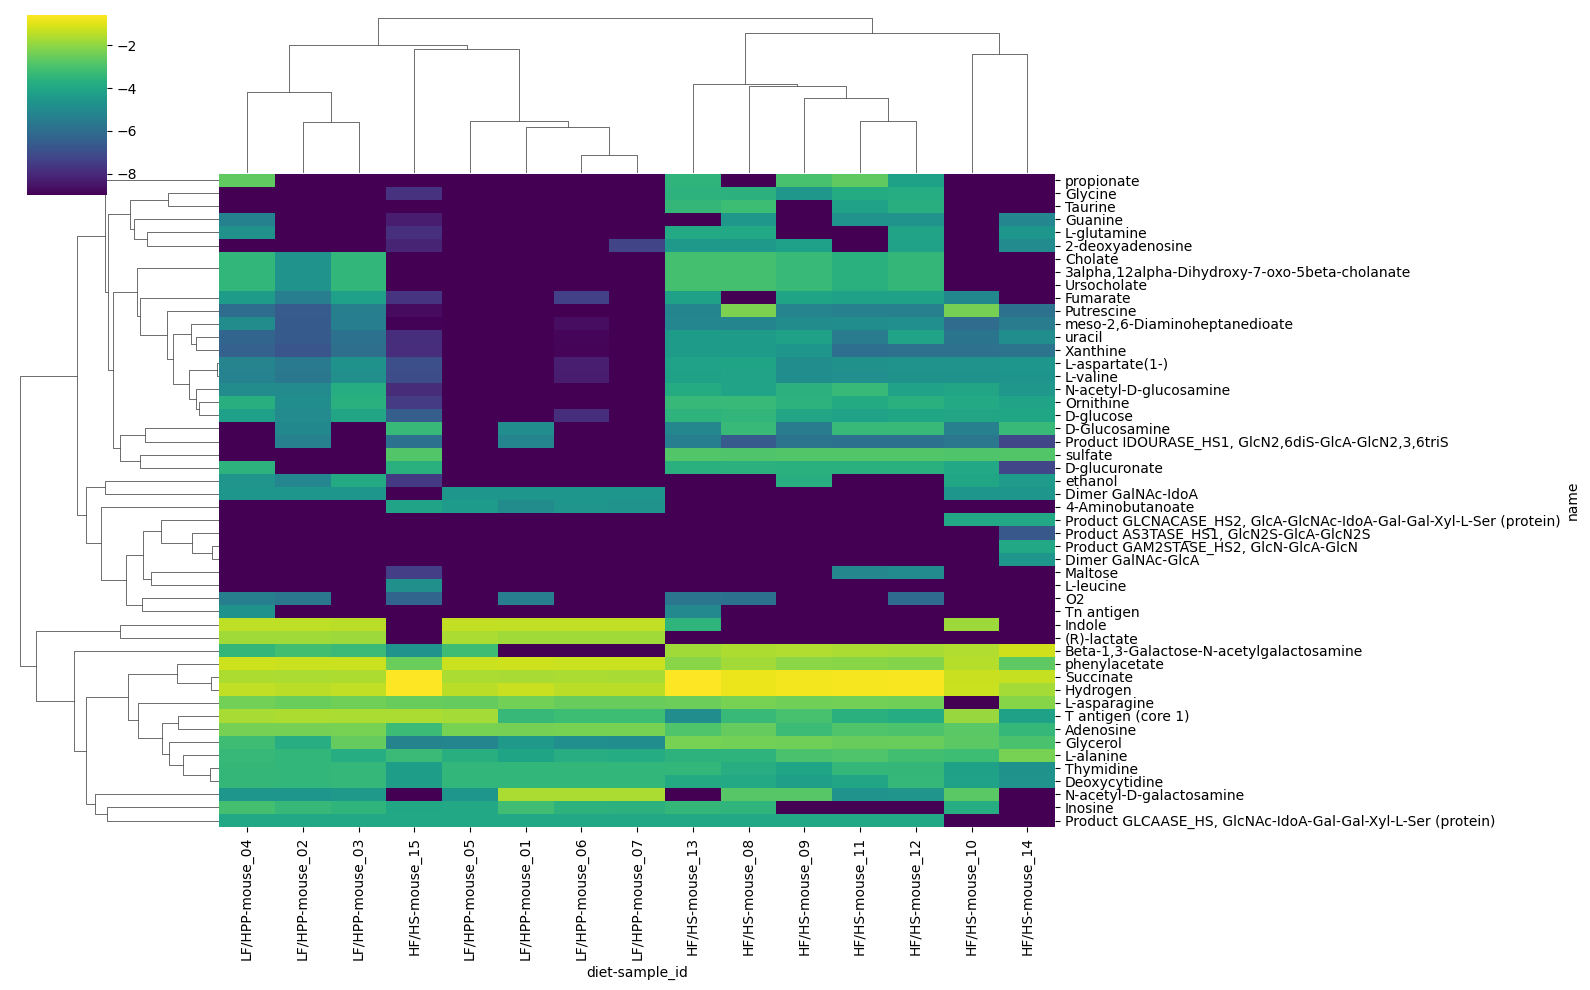

In [33]:
sns.clustermap(
    production_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
    figsize=(16, 10)      # size of the heatmap
)
plt.show()

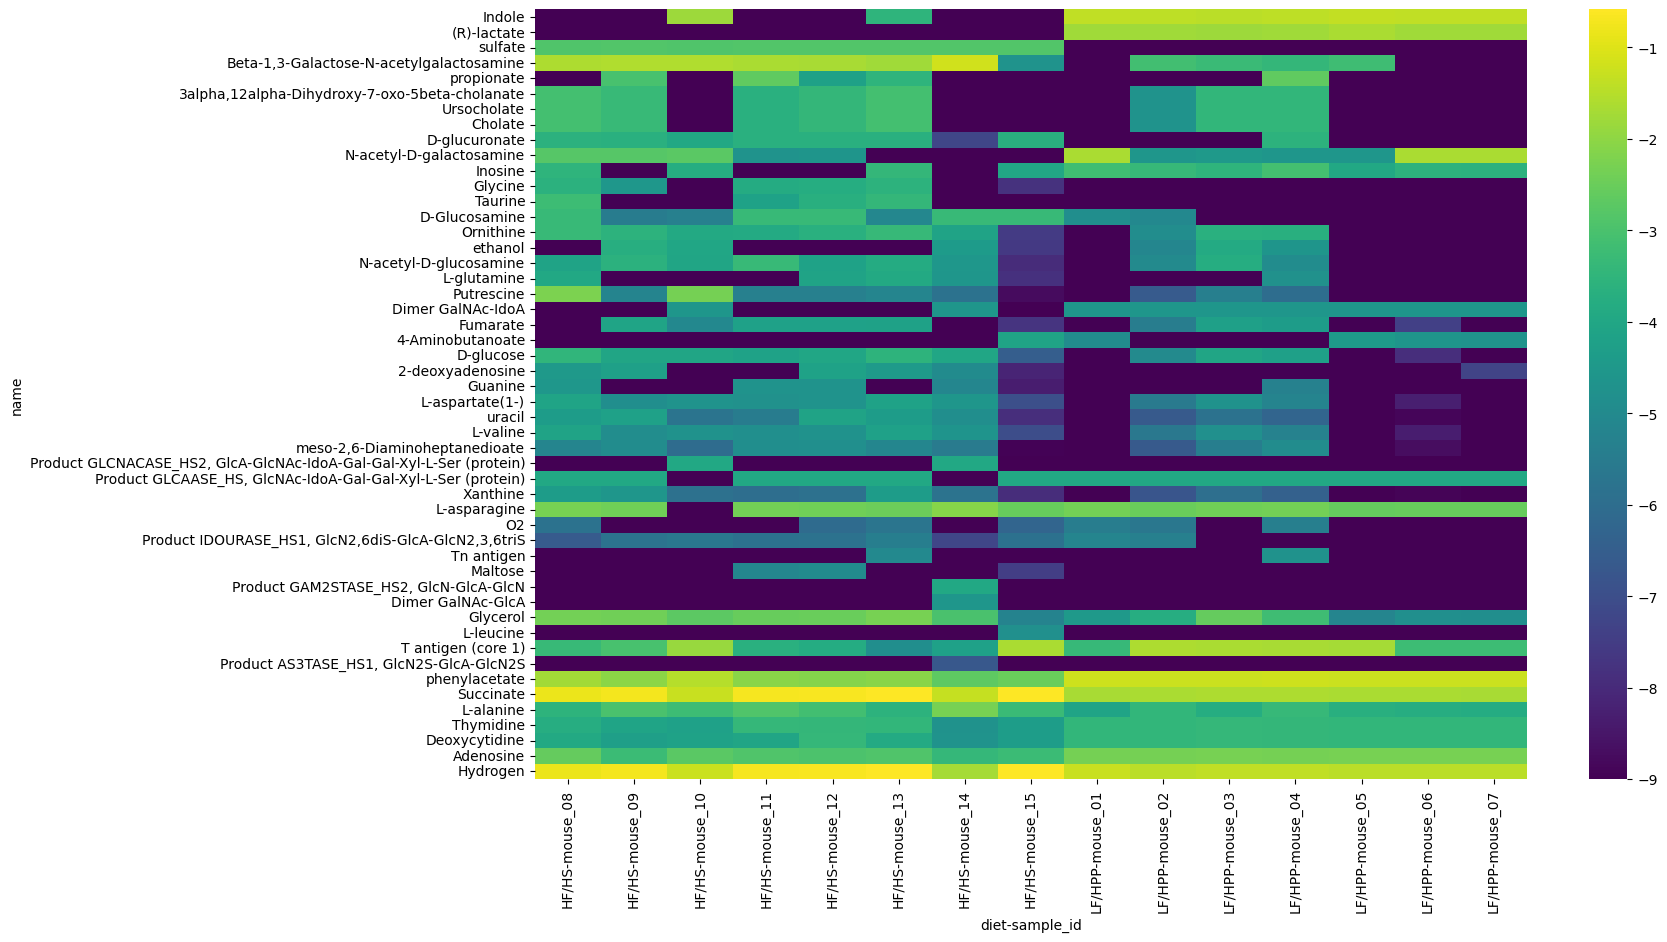

In [34]:
plt.figure(figsize=(16, 10))
sns.heatmap(
    production_pivot_var,  # take 50 highest fluxes
    cmap='viridis',
    yticklabels=True,    # show all metabolite names
)
plt.show()

# Knockout analysis

In [35]:
LF0 = ['mouse_01', 'mouse_02', 'mouse_03', 'mouse_04', 'mouse_05', 'mouse_06', 'mouse_07']
HF = ['mouse_08', 'mouse_09', 'mouse_10', 'mouse_11', 'mouse_12', 'mouse_13', 'mouse_14', 'mouse_15']

In [36]:
knockouts_lf0 = []
olds = []
for mouse in LF0:
    ko_raw = pd.read_table(f"results/lf0/knockouts/{mouse}_ko_raw.tsv", index_col=0)
    # ko_raw.replace(0, np.nan, inplace=True)
    ko_change = pd.read_table(f"results/lf0/knockouts/{mouse}_ko_change.tsv", index_col=0)
    old = ko_raw - ko_change
    olds.append(old)
    ko_log_change = np.log10(ko_raw + 1e-5) - np.log10(old + 1e-5)
    knockouts_lf0.append(ko_log_change)
knockouts_lf0_mean = np.mean(knockouts_lf0, axis=0)
olds[2]

/home/acs98/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/home/acs98/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/home/acs98/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/home/acs98/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)
/home/acs98/.local/lib/python3.10/site-packages/pandas/core/internals/blocks.py:366: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


,B_caccae,B_cellulosilyticus_WH2,B_ovatus,B_thetaiotaomicron,B_uniformis,B_vulgatus,C_aerofaciens,C_scindens,C_spiroforme,P_distasonis,R_obeum
B_caccae,NaN,0.044385,-4.933738e-03,0.095613,-7.537427e-03,0.095732,-5.878684e-03,-2.750702e-03,-1.034277e-02,0.016752,-1.350867e-02
B_cellulosilyticus_WH2,1.741149e-08,NaN,3.702725e-08,0.096400,1.286705e-08,0.096523,1.148519e-08,1.640287e-08,-4.314111e-05,0.024254,1.707418e-08
B_ovatus,-1.520699e-03,0.040480,NaN,0.096139,-2.121487e-03,0.096547,-1.953257e-03,-7.353178e-04,-4.181582e-03,0.020900,-3.590886e-03
B_thetaiotaomicron,1.236500e-12,0.039221,2.794001e-13,NaN,2.534999e-13,0.096523,3.954998e-13,1.969000e-13,3.674072e-10,0.024254,5.594995e-13
B_uniformis,1.236500e-12,0.039221,2.794006e-13,0.096400,NaN,0.096523,3.955000e-13,1.970000e-13,3.674072e-10,0.024254,5.594999e-13
B_vulgatus,1.236499e-12,0.039221,2.793998e-13,0.096400,2.535003e-13,NaN,3.955005e-13,1.968998e-13,3.674072e-10,0.024254,5.595004e-13
C_aerofaciens,1.236500e-12,0.039221,2.793000e-13,0.096400,2.533999e-13,0.096523,NaN,1.969000e-13,3.674072e-10,0.024254,5.594002e-13
C_scindens,1.236500e-12,0.039221,2.793980e-13,0.096400,2.535003e-13,0.096523,3.955000e-13,NaN,3.674072e-10,0.024254,5.593997e-13
C_spiroforme,1.236500e-12,0.039221,2.794015e-13,0.096400,2.535000e-13,0.096523,3.955000e-13,1.969468e-13,NaN,0.024254,5.594000e-13
P_distasonis,1.236500e-12,0.039221,2.794000e-13,0.096400,2.535003e-13,0.096523,3.955000e-13,1.969000e-13,3.674072e-10,NaN,5.594999e-13


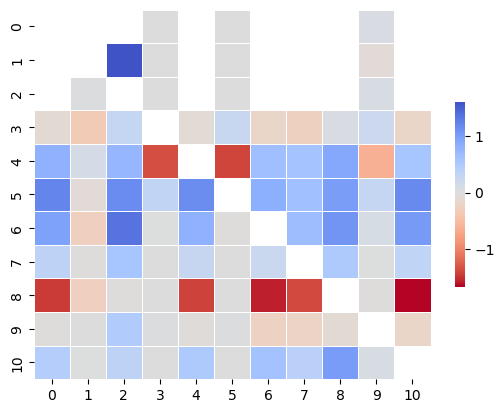

In [37]:
cmap = sns.color_palette("coolwarm_r", as_cmap=True)
sns.heatmap(knockouts_lf0_mean, 
            cmap=cmap,
            center=0,
            cbar_kws={"shrink": .5}, 
            linewidths=0.5,
            linecolor='w',
            # annot=True,
            fmt='.3f',
            # annot_kws={'size': 11}
            )
plt.savefig('results/lf0/knockouts/foldchange.png')
plt.show()

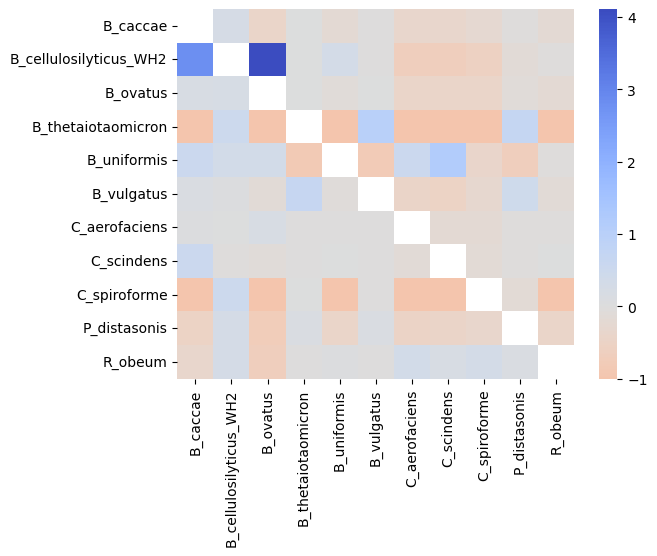

In [38]:
knockouts_rel_lf0 = []
for mouse in LF0:
    knockouts_rel_lf0.append(pd.read_table(f"results/lf0/knockouts/{mouse}_ko_relative.tsv", index_col=0))
sns.heatmap(knockouts_rel_lf0[0], cmap=cmap, center=0)
plt.savefig('results/lf0/knockouts/relative.png')
plt.show()

If you use the `grow` workflow that information is contained in `GrowthResults.exchanges` which maps out which metabolites are produced by each microbe and which ones are consumed. If species **A** produces _M_ and species **B** consumes it that would be a trophic interaction. If both consume it they might compete for it. A new interaction module is currently in the works, and it will give you that directly along with other measures such as total exchanges mass/carbon/nitrogen flux etc.

Yep, production rates are the secretion fluxes into the extracellular space. Some of those might be taken up by other microbes, but if you want to know what would be available for an organism that is (1) not part of your model right now and (2) resides in the same space as the microbes, then the production rates are exactly what you want.

# Interactions

In [41]:
for taxa in pfba_lf0[0].taxon.unique():
    plot_focal_interactions(pfba_lf0, taxa, f'results/lf0/interactions/interactions_{taxa}.html')
for taxa in pfba_hf0[0].taxon.unique():
    plot_focal_interactions(pfba_hf0, taxa, f'results/hf0/interactions/interactions_{taxa}.html')

In [42]:
MES(pfba_lf0).to_csv('results/lf0/interactions/mes.tsv', sep='\t')
MES(pfba_hf0).to_csv('results/hf0/interactions/mes.tsv', sep='\t')

In [43]:
interactions = []
for i in glob.glob('results/lf0/interactions/interactions_*.csv'):
    interactions.append(pd.read_csv(i, index_col=1))
interactions = pd.concat(interactions, axis=0)
interactions

,metabolite,partner,class,flux,sample_id,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction
focal,,,,,,,,,,,,,,
B_cellulosilyticus_WH2,ac[e],B_caccae,received,1.256192,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e)
B_cellulosilyticus_WH2,ac[e],B_ovatus,co-consumed,3.313618,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e)
B_cellulosilyticus_WH2,ac[e],B_thetaiotaomicron,co-consumed,0.048605,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e)
B_cellulosilyticus_WH2,ac[e],B_uniformis,received,3.508401,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e)
B_cellulosilyticus_WH2,ac[e],B_vulgatus,co-consumed,7.411545,mouse_01,acetate,59.04402,2,0,HMDB00042,"InChI=1S/C2H4O2/c1-2(3)4/h1H3,(H,3,4)/p-1",C00033,176.0,EX_ac(e)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
C_scindens,nac[e],P_distasonis,co-consumed,0.000002,mouse_04,Nicotinate,122.10146,6,1,HMDB01488,NaN,C00253,938.0,EX_nac(e)
C_scindens,nac[e],C_aerofaciens,co-consumed,0.000001,mouse_04,Nicotinate,122.10146,6,1,HMDB01488,NaN,C00253,938.0,EX_nac(e)
C_scindens,pnto_R[e],C_aerofaciens,co-consumed,0.000001,mouse_04,(R)-Pantothenate,218.22704,9,1,HMDB00210,"InChI=1S/C9H17NO5/c1-9(2,5-11)7(14)8(15)10-4-3...",C00864,988.0,EX_pnto_R(e)


In [44]:
interactions_summary = []
for i in glob.glob('results/lf0/interactions/summary_*.csv'):
    interactions_summary.append(pd.read_csv(i, index_col=1))
interactions_summary = pd.concat(interactions_summary, axis=0)
interactions_summary

,sample_id,partner,class,flux,mass_flux,C_flux,N_flux,n_ints
focal,,,,,,,,
C_spiroforme,mouse_01,B_caccae,co-consumed,0.001272,0.001272,0.042373,0.000000,2
C_spiroforme,mouse_01,B_caccae,provided,0.000237,0.000237,0.000000,0.000000,1
C_spiroforme,mouse_01,B_caccae,received,0.001484,0.001484,0.042373,0.014124,1
C_spiroforme,mouse_01,B_cellulosilyticus_WH2,co-consumed,0.003905,0.003905,0.117263,0.030383,5
C_spiroforme,mouse_01,B_cellulosilyticus_WH2,provided,0.007017,0.007017,0.224723,0.036493,5
...,...,...,...,...,...,...,...,...
C_scindens,mouse_07,P_distasonis,provided,0.021481,0.021481,0.003537,0.000278,3
C_scindens,mouse_07,P_distasonis,received,0.054562,0.054562,0.312791,2.261624,2
C_scindens,mouse_07,R_obeum,co-consumed,0.525312,0.525312,16.967807,2.261624,4


In [45]:
mes_lf0 = pd.read_table('results/lf0/interactions/mes.tsv', index_col=0)
mes_lf0

,metabolite,sample_id,MES,name,molecular_weight,C_number,N_number,hmdb,inchi,kegg.compound,pubchem.compound,reaction
0,26dap_M[e],mouse_02,1.500000,"meso-2,6-Diaminoheptanedioate",190.19706,7,2,NaN,NaN,NaN,NaN,EX_26dap_M(e)
1,26dap_M[e],mouse_03,1.500000,"meso-2,6-Diaminoheptanedioate",190.19706,7,2,NaN,NaN,NaN,NaN,EX_26dap_M(e)
2,26dap_M[e],mouse_04,1.600000,"meso-2,6-Diaminoheptanedioate",190.19706,7,2,NaN,NaN,NaN,NaN,EX_26dap_M(e)
3,26dap_M[e],mouse_06,1.000000,"meso-2,6-Diaminoheptanedioate",190.19706,7,2,NaN,NaN,NaN,NaN,EX_26dap_M(e)
4,2obut[e],mouse_01,1.333333,2-Oxobutanoate,101.08070,4,0,HMDB00005,"InChI=1S/C4H6O3/c1-2-3(5)4(6)7/h2H2,1H3,(H,6,7...",C00109,58.0,EX_2obut(e)
...,...,...,...,...,...,...,...,...,...,...,...,...
619,zn2[e],mouse_03,0.000000,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e)
620,zn2[e],mouse_04,0.000000,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e)
621,zn2[e],mouse_05,0.000000,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e)
622,zn2[e],mouse_06,0.000000,Zinc,65.40900,0,0,NaN,NaN,NaN,NaN,EX_zn2(e)
